# Livrable final — CVRPTW : minimisation de la durée totale

**CESI — Algorithmique et optimisation — 13 novembre 2026**

**Contexte métier.** Dans le cadre de la réponse de CesiCDP à l'appel de l'ADEME, nous étudions l'organisation de livraisons réalisées par une flotte homogène. Il faut servir les clients dans les créneaux convenus, respecter la charge des camions et limiter le temps total mobilisé. L'enjeu opérationnel est de réduire les trajets et attentes évitables tout en maintenant la faisabilité des livraisons. La durée est notre indicateur d'optimisation ; nous ne calculons pas ici une réduction d'émissions de CO₂, qui nécessiterait un modèle énergétique distinct.

Nous cherchons des tournées livrant chaque client exactement une fois, respectant la capacité, les fenêtres strictes et la fermeture du dépôt. Notre objectif est la **somme des durées des tournées**, avec trajets, attentes et services, pour des départs fixés à zéro. Le temps d’exécution du solveur est mesuré séparément.

La méthode associe notre constructeur et notre ILS à un HGS externe fourni par **PyVRP 0.12.2**, explicitement attribué à ses auteurs. Les expériences utilisent les données Solomon et Gehring–Homberger, sans les modifier. Conformément aux hypothèses professorales confirmées, les temps de trajet sont fixes et symétriques. Les fenêtres concernent le début des services.

Le rapport présente successivement le problème, sa formulation, l’algorithme, le protocole, les statistiques descriptives et les limites. Les fichiers individuels permettent de vérifier les solutions et les calculs.

<!-- RESULTATS_ACTUELS_DUREE_BEGIN -->
**Archive actuelle.** 472 solutions réalisables sur 356 instances, à budgets différents : 364 références dépassées, 24 références égalées et 84 écarts positifs. La moyenne conditionnelle des seuls écarts positifs est 2.5957 %, avec un maximum de 5.7589 %. Ces indicateurs ne certifient pas un gap à l’optimum temporel sur toutes les instances. Le tableau des effectifs et les mesures originales permettent de vérifier le périmètre de chaque résultat.
<!-- RESULTATS_ACTUELS_DUREE_END -->

**Validation statique finale.** Le complément 6.13 sépare 119 nouvelles résolutions pilotes, les cinq recherches de vérification des références publiées et les 646 essais historiques. Les références OR-Tools sont réalisables mais non certifiées optimales ; les mesures signées restent dans les fichiers d’audit. Les améliorations et régressions sont conservées.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'algo/duration.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from scripts.analyze_duration import analyze
runs,cases,sizes,repetitions,descriptive,analysis=analyze()
assert len(runs)==646 and len(cases)==356
assert runs.valid.all()
print('646 résolutions en durée ; 356 instances ; toutes réalisables.')

646 résolutions en durée ; 356 instances ; toutes réalisables.


## 1. Du réseau routier à la durée d’une tournée

Le dépôt et les clients forment les sommets d’un graphe orienté ; un arc représente un trajet possible. Les temps de trajet sont $c_{ij}$, les demandes $q_i$, les services $s_i$ et les fenêtres $[e_i,l_i]$. Une solution est une liste de tournées ; le dépôt 0 est implicite au départ et au retour.

Deux ordres de visite peuvent parcourir la même distance et produire des attentes différentes. Sur l’exemple suivant, le trajet total vaut 18 et les services totalisent 9 dans les deux cas. L’attente vaut 7 dans l’ordre 1 puis 2, contre 1 dans l’autre : les durées sont 34 et 28. Le deuxième ordre est meilleur pour notre objectif.

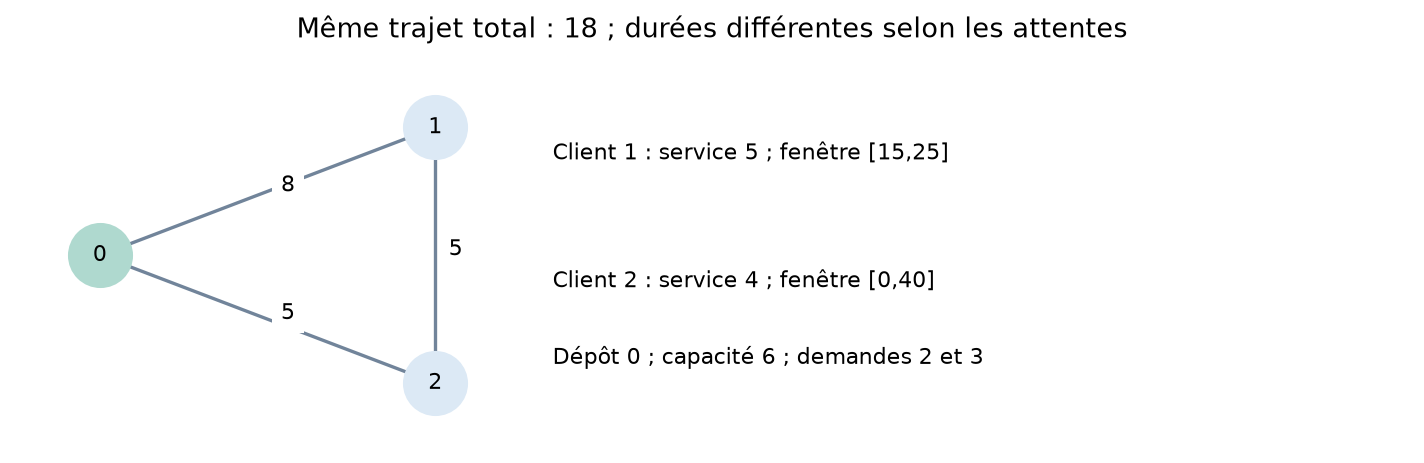

In [2]:
display(Image(filename=str(ROOT/'livraison/duree_figures/graphe.png')))

**Lecture du schéma.** Le sommet 0 représente le dépôt, et les sommets 1 et 2 représentent deux clients. Les nombres sur les liaisons sont les temps de trajet : 8, 5 et 5 unités de temps. Chaque liaison représente ici deux arcs opposés de même coût. Les informations à droite complètent la géométrie : demandes, capacité, services et fenêtres horaires. Les demandes totalisent 5 pour une capacité de 6 ; la capacité autorise donc à regrouper les deux clients.

**Intérêt et lien avec la suite.** Ce petit réseau permet de comprendre les données avant d'introduire les équations. Les deux ordres de visite ont un trajet total de 18, mais le dessin spatial ne suffit pas à déterminer lequel termine le plus tôt. Le diagramme suivant reprend exactement ces clients pour montrer l'effet des fenêtres horaires.

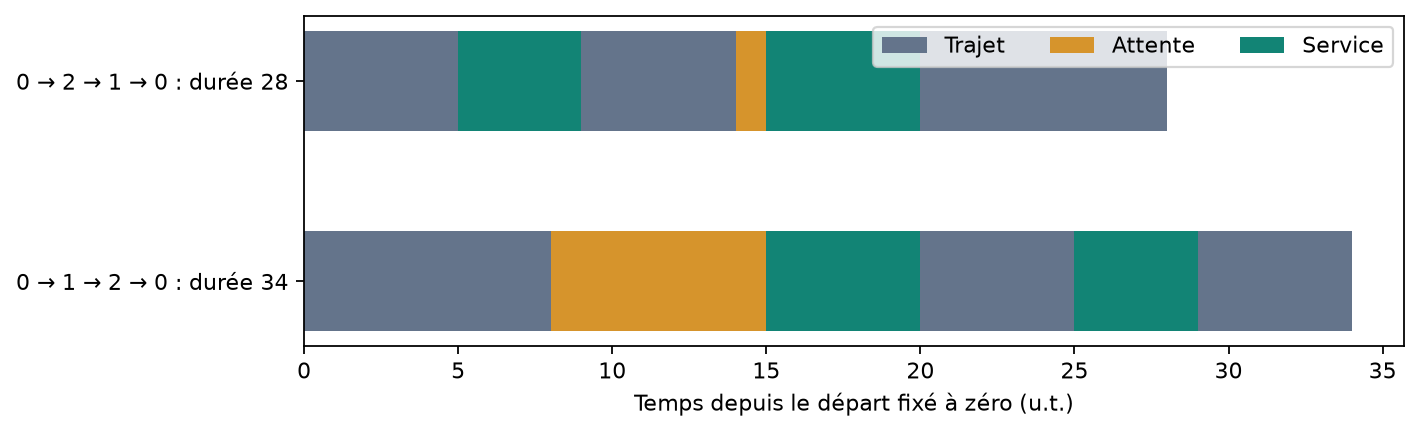

In [3]:
display(Image(filename=str(ROOT/'livraison/duree_figures/attentes.png')))

**Lecture du diagramme.** Chaque ligne décrit une tournée complète, depuis le départ à zéro jusqu'au retour au dépôt. Les segments gris correspondent aux trajets, les segments orange aux attentes et les segments verts aux services. Dans l'ordre 0 → 1 → 2 → 0, le véhicule atteint le client 1 à 8 et attend jusqu'à 15 : la durée finale est 34. Dans l'ordre inverse, il sert d'abord le client 2, atteint le client 1 à 14 et attend seulement une unité : il revient à 28.

**Intérêt et lien avec le modèle.** Le trajet total et les services sont identiques ; les six unités gagnées proviennent uniquement de l'attente. Ce diagramme explique concrètement pourquoi nous minimisons la durée et pourquoi un gain de distance ne se transpose pas automatiquement en gain de durée. Il prépare la récurrence des horaires et les variables de retour de la formulation mathématique.

In [4]:
from algo.model import Instance
from algo.verify import verify
m=np.array([[0,80,50],[80,0,50],[50,50,0]],float)
toy=Instance('exemple',np.zeros((3,2)),np.array([0,2,3]),np.array([0,50,40]),np.array([0,150,0]),np.array([600,250,400]),m,6.,1,600.)
for route in [[[1,2]],[[2,1]]]:
    v=verify(route,toy)
    assert v['valid']
    print(route,'trajets',v['travel']/10,'attente',v['waiting']/10,'services',toy.service.sum()/10,'durée',v['duration']/10)

[[1, 2]] trajets 18.0 attente 7.0 services 9.0 durée 34.0
[[2, 1]] trajets 18.0 attente 1.0 services 9.0 durée 28.0


## 2. Complexité et vérification du modèle

Le problème de décision associé demande s'il existe une solution réalisable de durée totale au plus B. Nous montrons sa difficulté par une réduction **du TSP vers notre CVRPTW statique**, et non dans le sens inverse.

Considérons une instance du TSP symétrique à m sommets, avec des coûts entiers non négatifs $c_{ij}$ et un seuil B. Un sommet devient le dépôt et les $m-1$ autres deviennent les clients. Nous fixons un seul véhicule, $q_i=1$, $Q=m-1$, des services nuls, et les fenêtres $[0,H]$ avec $H=m\max(1,\max_{i,j}c_{ij})$. Les temps de trajet reprennent exactement les coûts du TSP. Toutes les capacités et fenêtres sont alors non bloquantes pour un circuit hamiltonien ; aucun temps d'attente n'est imposé.

Un circuit du TSP de coût au plus B donne donc une tournée CVRPTW de durée au plus B. Réciproquement, une solution CVRPTW de cette instance doit utiliser son unique véhicule pour visiter tous les clients exactement une fois et revenir au dépôt ; elle décrit un circuit hamiltonien dont le coût est au plus sa durée, donc au plus B. La transformation utilise une matrice de taille quadratique et un horizon de représentation binaire polynomiale. L'optimisation est ainsi **NP-difficile**.

Pour la version de décision à données entières ou rationnelles encodées, une liste de tournées est un certificat de taille polynomiale. Nous vérifions couverture, charges, fenêtres, retours et durée par propagation des horaires au plus tôt. Cette vérification est polynomiale ; la version de décision est donc **NP-complète**. La preuve concerne le problème général statique : elle ne prétend pas démontrer la difficulté de chaque instance particulière ni l'optimalité d'une métaheuristique.

Le PLNE de `controle/plne.py` est réellement résolu par HiGHS avec le coût placé sur les variables de retour $R_k$. Sur dix petits cas de 3 à 5 clients, nous comparons son résultat à une énumération indépendante des tournées et partitions. Les deux méthodes prouvent les mêmes optimums en durée. Un cas comprend des arcs nuls pour vérifier que le flot empêche les cycles isolés.

| instance | n | optimum | returned | Comparaison / statut | calculation_s |
| --- | --- | --- | --- | --- | --- |
| exact-duration-0 | 3 | 69,400 | 69,400 | Optimum atteint | 0,138 |
| exact-duration-1 | 4 | 77,600 | 77,600 | Optimum atteint | 0,137 |
| exact-duration-2 | 5 | 107,100 | 107,100 | Optimum atteint | 0,654 |
| exact-duration-3 | 3 | 86,200 | 86,200 | Optimum atteint | 0,057 |
| exact-duration-4 | 4 | 88,200 | 88,200 | Optimum atteint | 0,147 |
| exact-duration-5 | 5 | 106,100 | 106,100 | Optimum atteint | 0,788 |
| exact-duration-6 | 3 | 96,400 | 96,400 | Optimum atteint | 0,089 |
| exact-duration-7 | 4 | 74,900 | 74,900 | Optimum atteint | 0,138 |
| exact-duration-8 | 5 | 109,100 | 109,100 | Optimum atteint | 0,652 |
| exact-duration-9 | 3 | 66,000 | 66,000 | Optimum atteint | 0,041 |


Ces dix cas contrôlent la formulation ; ils ne démontrent pas l’optimalité des solutions à 100–1 000 clients.

![Graphe orienté avec dépôt de départ et de retour virtuels.](../livraison/figures_final_static/graphe_modele.png)

**Lecture du schéma.** o et r sont deux copies du même dépôt physique ; 1 et 2
sont des clients. Les flèches sont les décisions possibles de visite. Les deux
sens entre clients ont le même temps, mais leur ordre peut modifier l'attente.
Il n'y a pas de trafic dépendant de l'heure. Cette séparation départ/retour
prépare les variables d'arcs et les contraintes C3, C6 et C7 ci-dessous.


## 3. Modélisation mathématique du CVRPTW en durée

Nous formalisons le **CVRPTW statique étudié ici** : un dépôt unique, des véhicules homogènes, des livraisons indivisibles, une tournée au plus par véhicule et des trajets fixes et symétriques. L'attente avant ouverture est autorisée. Le début du service doit appartenir à la fenêtre du client et le retour doit respecter la fermeture du dépôt. Les bornes sont inclusives. Le trafic variable, les ramassages, les dépôts multiples et les flottes hétérogènes ne font pas partie des expériences réalisées.

**Ensembles et indices.** Le nombre de clients est l'entier $n\ge1$. Leur ensemble est $C=\{1,\ldots,n\}$. Le nombre maximal de véhicules est l'entier $K\ge0$ et leur ensemble d'indices est $\mathcal K=\{1,\ldots,K\}$. Ainsi, $n$ et $K$ sont des nombres ; $C$ et $\mathcal K$ sont des ensembles. L'écriture $\forall i\in C$ signifie « pour chaque client i appartenant à C ». Elle ne désigne pas une boucle « tant que ».

Nous représentons le dépôt physique par deux sommets : $o$ pour le départ et $r$ pour le retour. Cette duplication permet de distinguer les heures de départ et de retour ; elle n'ajoute pas un deuxième dépôt réel. Les sommets et arcs autorisés sont :

$$V=C\cup\{o,r\},$$
$$A=(\{o\}\times C)\cup\{(i,j)\in C\times C:i\ne j\}\cup(C\times\{r\}).$$

Les véhicules peuvent aller du départ à un client, entre deux clients distincts, puis d'un client au retour. Aucune boucle sur un même sommet n'est autorisée. Aucun arc n'entre dans o et aucun arc ne quitte r.

**Des fenêtres par objet aux fenêtres par client.** Les benchmarks fournissent une demande et une fenêtre par client, sans détail des objets. Nous interprétons donc un client comme une livraison agrégée effectuée en un seul passage. Si les objets $a\in O_i$ ont des demandes $q_a$ et doivent partager un même début de livraison chez i, l'agrégation serait $q_i=\sum_{a\in O_i}q_a$, $e_i=\max_{a\in O_i}e_a$ et $l_i=\min_{a\in O_i}l_a$. Une intersection vide rendrait cette livraison commune impossible. Des objets livrés à des horaires différents ou plusieurs visites au même client demanderaient un autre modèle ; nous ne prétendons pas traiter ce cas avec les données agrégées actuelles.

**Paramètres.** Pour chaque client $i\in C$, soient $q_i,s_i,e_i,l_i\in\mathbb R_{\ge0}$ : sa demande est $q_i$, sa durée de service $s_i$ et sa fenêtre de début de service $[e_i,l_i]$. Soient $Q,H\in\mathbb R_{>0}$ la capacité commune et la fermeture du dépôt. Comme dans les données acceptées par `Instance`, nous supposons $0\le e_i\le l_i\le H$ pour tout $i\in C$. Pour chaque arc $(i,j)\in A$, soient $d_{ij},c_{ij}\in\mathbb R_{\ge0}$ sa distance et son temps de trajet. Les départs sont fixés au temps zéro. Dans les benchmarks du projet, temps de trajet et distances ont les mêmes valeurs numériques ; le modèle distingue néanmoins leurs rôles et leurs unités.

**Pourquoi fixer le départ à zéro ?** Nous supposons que le temps mobilisé de chaque véhicule utilisé est compté depuis une même origine, l'ouverture du dépôt. Cette convention simplifie les horaires et aligne le PLNE, notre contrôleur et PyVRP ; ce n'est pas une obligation générale du CVRPTW et correspond au périmètre professoral confirmé pour cette finalisation. Si les départs $D_k$ devenaient des décisions libres, il faudrait minimiser $\sum_k(R_k-D_k)$ et adapter les contraintes de départ ainsi que l'évaluation de tous les témoins. Retarder le départ peut éviter une attente sur tournée : les pourcentages des deux conventions ne seraient donc pas interchangeables. Cette extension n'est pas implémentée dans les expériences présentées.

**Variables de décision et domaines.**

$$x_{ij}^k\in\{0,1\}\quad\forall(i,j)\in A,\ \forall k\in\mathcal K.$$

Pour chaque arc et chaque véhicule, x vaut un si le véhicule emprunte cet arc, et zéro sinon.

$$y_i^k\in\{0,1\}\quad\forall i\in C,\ \forall k\in\mathcal K,\qquad
u_k\in\{0,1\}\quad\forall k\in\mathcal K.$$

La variable y vaut un si le client i est affecté au véhicule k. La variable u vaut un si le véhicule k est utilisé.

$$t_i\in\mathbb R_{\ge0}\quad\forall i\in C,\qquad
R_k\in\mathbb R_{\ge0}\quad\forall k\in\mathcal K.$$

La variable t est l'heure de **début du service**, pas l'heure d'arrivée. La variable R est l'heure de retour au dépôt. Les bornes horaires sont imposées ci-dessous.

Enfin, $f_{ij}^k\in\mathbb R_{\ge0}$, pour chaque $(i,j)\in A$ et chaque $k\in\mathcal K$, est un flot artificiel assurant la connexion au dépôt. Il représente un outil mathématique, pas la marchandise dans le camion.

### 3.1. Fonction objectif : minimiser la durée totale

$$\boxed{\min T=\sum_{k\in\mathcal K}R_k}.$$

Chaque véhicule part à zéro. $R_k$ est donc sa durée de tournée, retour au dépôt compris ; $R_k=0$ s’il n’est pas utilisé. Nous minimisons la somme des temps mobilisés, et non le retour du dernier véhicule $\max_kR_k$ ni le temps de calcul du programme.

Pour une solution réalisable, cette durée se décompose en :

$$T=\sum_{k\in\mathcal K}\sum_{(i,j)\in A}c_{ij}x_{ij}^k+\sum_{i\in C}s_i+\sum_{i\in C}w_i,$$

où $w_i$ est l’attente avant le début du service, calculée à partir des horaires. La somme des services est constante pour une instance : elle est comptée mais ne constitue pas un gain que l’algorithme peut supprimer. Trajets et attentes peuvent varier. Les véhicules restent limités par la flotte disponible, sans priorité lexicographique ni coût fixe ajouté.

### 3.2. Contraintes et lecture opérationnelle

**C1 — Affecter chaque client exactement une fois.**

$$\sum_{k\in\mathcal K}y_i^k=1\qquad\forall i\in C.$$

Pour chaque client i, la somme des affectations vaut un : un seul véhicule réalise l'intégralité de sa livraison. Aucun client ne peut être oublié ou réparti entre plusieurs camions.

**C2 — Assurer une entrée et une sortie avec le véhicule affecté.**

$$\sum_{j:(j,i)\in A}x_{ji}^k=y_i^k,
\qquad\sum_{j:(i,j)\in A}x_{ij}^k=y_i^k
\qquad\forall i\in C,\ \forall k\in\mathcal K.$$

Pour chaque client et chaque véhicule, une affectation impose exactement une entrée et une sortie. Sans affectation, ce véhicule n'emprunte aucun arc entrant ou sortant de ce client. Les indices des sommes sont limités aux arcs autorisés de A.

**C3 — Partir du dépôt et y revenir, au plus une fois par véhicule.**

$$\sum_{j\in C}x_{oj}^k=u_k,
\qquad\sum_{i\in C}x_{ir}^k=u_k
\qquad\forall k\in\mathcal K.$$

Chaque véhicule utilisé effectue un départ et un retour. Un véhicule inutilisé n'en effectue aucun. On autorise donc l'utilisation de moins de K camions. La borne $\sum_{k\in\mathcal K}u_k\le K$ est automatiquement satisfaite, puisque u est binaire et que $\mathcal K$ contient K véhicules.

**C4 — Respecter la capacité de chaque camion.**

$$\sum_{i\in C}q_iy_i^k\le Qu_k
\qquad\forall k\in\mathcal K.$$

Pour chaque véhicule, la somme des quantités affectées ne dépasse pas Q. Cette somme est la charge à emporter au départ pour des livraisons pures. Elle diminue ensuite pendant la tournée ; il n'y a aucun ramassage. Le code peut donc contrôler la même contrainte en additionnant les demandes de la tournée. Les unités de demande ne sont pas multipliées par dix.

**C5 — Commencer le service dans la fenêtre du client.**

$$e_i\le t_i\le l_i\qquad\forall i\in C.$$

Pour chaque client, le début du service se situe entre ouverture et fermeture, bornes comprises. Une arrivée avant l'ouverture est possible avec attente. La fin $t_i+s_i$ peut dépasser $l_i$ : notre projet n'impose pas une fenêtre sur la fin du service.

**C6 — Respecter l'ordre temporel des trajets et services.**

Posons $s_{\max}=\max_{i\in C}s_i$, $c_{\max}=\max_{(i,j)\in A}c_{ij}$ et $M=H+s_{\max}+c_{\max}$. Cette borne est valide sous les hypothèses d'horizon précédentes.

$$t_j\ge c_{oj}-M(1-x_{oj}^k)
\qquad\forall j\in C,\ \forall k\in\mathcal K.$$

Pour chaque client j et chaque véhicule k, si l'arc du dépôt vers j est utilisé, le service ne commence pas avant la fin du trajet depuis le départ au temps zéro.

$$t_j\ge t_i+s_i+c_{ij}-M(1-x_{ij}^k)
\qquad\forall i,j\in C,\ i\ne j,\ \forall k\in\mathcal K.$$

Pour chaque paire de clients distincts et chaque véhicule, emprunter l'arc de i vers j impose de terminer le service chez i puis le trajet avant de commencer chez j. Si cet arc n'est pas utilisé, M désactive l'implication. Une borne par arc pourrait renforcer une résolution exacte sans changer les règles métier.

Les contraintes imposent des horaires réalisables ; minimiser la somme des retours sélectionne une durée minimale pour les tournées retenues. Une fois l'ordre fixé, `verify()` recalcule les horaires au plus tôt : arrivée = fin précédente + trajet ; début = maximum entre arrivée et ouverture ; fin = début + service.

**C7 — Relier le retour à la tournée et respecter la fermeture du dépôt.**

$$R_k\ge t_i+s_i+c_{ir}-M(1-x_{ir}^k)
\qquad\forall i\in C,\ \forall k\in\mathcal K,$$
$$0\le R_k\le Hu_k\qquad\forall k\in\mathcal K.$$

Si le véhicule k revient directement du client i, alors $x_{ir}^k=1$ : la première inégalité impose de terminer le service puis le trajet de retour avant $R_k$. La seconde impose la fermeture du dépôt et fixe $R_k=0$ pour un véhicule inutilisé. Un retour exactement à H est autorisé.

**Pourquoi simplifier cette contrainte ?** Dans la version précédente, nous écrivions aussi $R_k\le t_i+s_i+c_{ir}+M(1-x_{ir}^k)$. Cette borne supérieure supplémentaire est redondante à l'optimum pour notre objectif $\min\sum_k R_k$ : la minimisation choisit déjà la plus petite valeur permise par la borne inférieure. Nous la retirons de la formulation en durée et du solveur exact correspondant. Cela conserve l'objectif optimal et les tournées réalisables, sans imposer une égalité à tous les horaires non optimaux. Le mode historique en distance conserve cette égalité explicite, car son objectif ne minimise pas les retours.

**Exemple.** Si le dernier service commence à 50, dure 10 et est suivi de 5 unités de trajet, alors $R_k\ge65$ ; la minimisation donne 65. Si le dépôt ferme à 60, cette tournée est interdite. Supprimer tout C7 serait donc incorrect : $R_k$ ne serait plus relié au trajet de retour et pourrait artificiellement valoir zéro. Nous retirons donc uniquement la borne supérieure redondante ; le retour avant fermeture reste obligatoire. Les dix petits cas de contrôle conservent leur optimum après cette simplification.

**C8 — Interdire les cycles de clients isolés du dépôt.**

$$0\le f_{ij}^k\le nx_{ij}^k
\qquad\forall(i,j)\in A,\ \forall k\in\mathcal K,$$
$$f_{ir}^k=0\qquad\forall i\in C,\ \forall k\in\mathcal K.$$

Le flot artificiel ne passe que sur un arc utilisé. Il fournit une unité par client et n'a plus rien à transporter lors du retour au dépôt.

$$\sum_{j:(j,i)\in A}f_{ji}^k-\sum_{j:(i,j)\in A}f_{ij}^k=y_i^k
\qquad\forall i\in C,\ \forall k\in\mathcal K,$$
$$\sum_{j\in C}f_{oj}^k=\sum_{i\in C}y_i^k
\qquad\forall k\in\mathcal K.$$

Chaque client affecté consomme une unité reçue du dépôt. Le dépôt en émet autant que de clients affectés au véhicule. Un cycle isolé ne peut pas satisfaire cette consommation : en additionnant les équations de ses clients, tous les flots internes s'annulent alors qu'une consommation strictement positive resterait nécessaire. Le flot empêche ainsi les sous-tournées, même lorsque des temps tronqués sont nuls.

**Convention numérique et représentation dans le programme.** Les références DIMACS utilisent chaque arc euclidien tronqué à une décimale. `algo/data.py` calcule sa valeur entière à l'échelle dix et multiplie fenêtres et services par dix. Les coûts affichés sont reconvertis. Les dépôts o et r du PLNE correspondent tous deux à l'indice 0 du code ; les retours sont ajoutés implicitement aux listes de tournées. Les contraintes restent obligatoires, quelle que soit la métaheuristique choisie.



**Pourquoi le grand M est valide.** Les bornes $0\le t_i,t_j\le H$ impliquent $t_i+s_i+c_{ij}-t_j\le H+s_{\max}+c_{\max}$. Cette valeur désactive donc la propagation d'un arc non utilisé. Des bornes par arc peuvent renforcer le solveur exact sans modifier les solutions autorisées. Le modèle contient de l'ordre de $Kn^2$ variables d'arcs/flots et contraintes : l'exact sert ici aux petits cas.

## 4. Algorithme et lien avec le code

### Comprendre les méthodes : principe général et application au projet

Une **heuristique constructive** fabrique une première solution sans garantie de meilleure qualité possible. Une **recherche locale** l'améliore par des transformations limitées. Une **métaheuristique**, comme l'ILS, le recuit ou le HGS, organise l'exploration pour limiter les blocages. Une **méthode exacte** apporte une preuve lorsque sa résolution aboutit ; sa taille et son temps de calcul limitent ici son utilisation. Ces rôles sont complémentaires.

Dans tout ce qui suit, la qualité finale est $T(S)=\sum_k T_k$, somme des trajets, attentes et services avec départs à zéro. Les scores intermédiaires d'une construction peuvent utiliser une économie d'arcs pour guider les choix ; ils ne remplacent pas cet objectif. Chaque solution retenue doit satisfaire couverture unique, capacité, fenêtres, flotte maximale et fermeture du dépôt.

**Vue d'ensemble des deux profils effectivement mesurés.**

![Rôle des méthodes dans le profil initial et dans le profil renforcé.](../livraison/duree_figures/architecture_algorithmes.png)

**Lecture du schéma.** La ligne supérieure correspond à la campagne initiale : le constructeur fournit une solution, notre ILS l'améliore, puis le HGS externe poursuit la recherche avant validation indépendante. La ligne inférieure correspond au profil renforcé : plusieurs constructions alimentent une recherche locale externe et un réservoir de tournées ; le partitionnement choisit une combinaison réalisable. Le HGS de cette ligne représente les continuations ciblées, déclenchées dans des expériences supplémentaires, et non un appel obligatoire dans chaque exécution courte. Les pointillés signalent cette continuation optionnelle ; le contrôle indépendant, lui, reste systématique, avec ou sans HGS. Les deux chaînes se terminent par le même contrôleur et le même objectif en durée.

**Intérêt et continuité.** Ce schéma relie le modèle mathématique aux composants du programme. Il évite d'attribuer au profil initial les mécanismes ajoutés ensuite. Les paragraphes suivants expliquent chaque bloc ; les extraits de code et les statistiques montrent ensuite leur mise en œuvre et leurs effets observés. Les budgets et les différences de profils restent identifiés dans les résultats.

**1. Construction par regret-2 — placer d'abord les clients qui risquent de devenir difficiles.**

En général, une insertion gloutonne place le client dont l'ajout paraît le moins coûteux. Le regret-2 considère aussi le coût d'attendre : pour un client i, si ses deux meilleures possibilités coûtent $b_i^{(1)}$ et $b_i^{(2)}$, son regret vaut $r_i=b_i^{(2)}-b_i^{(1)}$. Un regret élevé invite à le placer avant que sa meilleure possibilité ne disparaisse. Par exemple, un client ayant des coûts 2 et 12 est plus fragile qu'un client ayant des coûts 3 et 4.

Dans `algo/kernels.py::repair_fast`, nous calculons la meilleure position réalisable dans chaque tournée, puis comparons ces possibilités entre tournées. Les clients ayant moins de possibilités ont priorité ; les autres sont départagés par leur regret. Un score d'ouverture d'une nouvelle tournée participe au classement constructif. `algo/duration.py::construct` essaie douze constructions et sélectionne la solution complète de plus faible durée, recalculée par `verify`. L'intérêt est de construire un départ réalisable en anticipant les clients contraints ; l'insertion reste une heuristique et peut produire un départ médiocre.

**2. Clarke–Wright — regrouper des clients en économisant des retours au dépôt.**

Le principe des économies commence avec une tournée par client. Relier directement i et j peut supprimer deux passages par le dépôt. L'économie spatiale est $g_{ij}=d_{i0}+d_{0j}-d_{ij}$. Si les distances au dépôt valent 8 et 5, et la liaison directe 5, l'économie vaut 8. Les paires offrant de fortes économies sont examinées en premier.

Dans `algo/savings.py::savings_construct`, nous ne fusionnons que des extrémités de tournées distinctes, après vérification de la capacité et de tous les horaires ; l'ordre inverse est aussi essayé si nécessaire. Le profil renforcé introduit du bruit dans le classement aux départs suivants pour diversifier les regroupements. Les économies de distance guident la construction, mais `algo/duration_refine.py` évalue et conserve les solutions améliorées selon leur durée complète. L'intérêt est de proposer rapidement des regroupements différents de ceux du regret-2 ; une économie de trajet n'est jamais, à elle seule, une preuve de gain temporel.

**3. Insertion séquentielle — remplir progressivement une tournée.**

Le principe consiste à choisir un premier client, puis à insérer les suivants aux positions jugées intéressantes tant que les contraintes restent satisfaites. Lorsqu'aucune insertion n'est possible, une nouvelle tournée est ouverte. Avec des fenêtres horaires, il faut examiner le décalage des services suivants, pas seulement les arcs ajoutés. Cette famille est notamment étudiée par [Solomon, 1987](https://pubsonline.informs.org/doi/10.1287/opre.35.2.254).

Notre variante `algo/sequential.py::sequential_insert` commence, dans le réglage retenu, avec un client éloigné du dépôt. Elle combine le surcoût de trajet et le décalage temporel d'insertion avec `time_weight=0.5`, puis tient compte de l'éloignement du client avec `saving_weight=1`. Les horaires au plus tard autorisés vérifient que l'insertion ne bloque pas les clients suivants. Un bruit dépendant de la graine diversifie les choix. Cette construction fournit un autre départ au profil renforcé ; nous ne présentons pas cette adaptation comme une reproduction exacte de tous les réglages de Solomon.

**4. Recherche locale — améliorer une solution en modifiant quelques visites.**

Pour une solution S, un voisinage $N(S)$ est l'ensemble des solutions atteignables avec les mouvements autorisés. Une descente cherche une candidate $S'\in N(S)$ telle que $\Delta=T(S')-T(S)<0$, puis recommence. Un optimum local ne garantit pas l'optimum global : une amélioration peut nécessiter un mouvement absent du voisinage, ou une dégradation intermédiaire. Une descente échantillonnée ne prouve même pas avoir examiné tous les voisins.

| Mouvement | Principe général | Utilité et précaution en CVRPTW |
|---|---|---|
| Relocate | Retirer un client et l'insérer ailleurs | Rééquilibrer les tournées ; recalculer charges et horaires des tournées touchées |
| Swap | Échanger deux clients à leurs positions | Changer une affectation sans retirer de visite ; vérifier la propagation des horaires |
| 2-opt | Inverser une portion d'une tournée | Modifier l'ordre ; une inversion peut devenir interdite par les fenêtres |
| 2-opt* | Échanger les fins de deux tournées | Réorganiser plusieurs affectations simultanément ; vérifier les deux tournées obtenues |
| SWAP* | Retirer un client de chaque tournée et rechercher leurs nouvelles positions dans l'autre | Explorer davantage de possibilités qu'un échange aux positions initiales |

Notre `algo/duration_moves.py::walk` implémente les quatre premiers mouvements et recalcule les durées des tournées modifiées. SWAP* appartient à la recherche locale externe de PyVRP, utilisée par le HGS et le profil renforcé. Deux clients géographiquement proches peuvent avoir des créneaux incompatibles : le voisinage externe prend aussi en compte des indications d'attente et de retard. Nous avons testé 40, 60, 80 puis 120 voisins ; élargir ce choix ouvre des mouvements, mais augmente leur coût. Ces mécanismes externes sont documentés dans le [code PyVRP 0.12.2 des voisinages](https://github.com/PyVRP/PyVRP/blob/v0.12.2/pyvrp/search/neighbourhood.py).

**5. ILS — perturber, améliorer, puis choisir où poursuivre.**

L'Iterated Local Search part d'une solution, applique une recherche locale, perturbe l'état retenu, puis améliore la candidate. Un critère d'acceptation choisit la solution servant de nouveau point de départ. La perturbation doit être suffisante pour sortir d'un blocage, tout en conservant une partie de la structure utile. Ce cadre est décrit par [Lourenço, Martin et Stützle](https://arxiv.org/abs/math/0102188).

Dans `algo/duration.py::search`, notre ILS tente jusqu'à quatre perturbations réalisables, suivies d'une descente échantillonnée. La candidate peut devenir le nouvel état si elle reste à moins de 0,5 % du meilleur coût connu. L'archive est mise à jour uniquement en cas d'amélioration stricte. Après cent cycles sans record, la recherche repart de cette archive. Nous conservons donc séparément l'état exploré et la meilleure solution. L'ILS appartient à la campagne initiale et au profil hybride initial ; le profil `duration_refined` utilise une orchestration différente, fondée sur plusieurs constructions et une intensification externe.

**6. Recuit simulé — accepter parfois une dégradation contrôlée.**

Le recuit accepte une amélioration et peut accepter une hausse $\Delta>0$ avec la probabilité $\exp(-\Delta/\theta)$, où $\theta>0$ est la température. Une température élevée facilite les déplacements dégradants ; son refroidissement concentre progressivement la recherche. À titre d'exemple, pour $\Delta=2$ et $\theta=4$, la probabilité vaut environ 0,607, contre 0,135 si $\theta=1$. Accepter une hausse ne signifie pas abandonner le meilleur résultat déjà trouvé.

Notre variante de comparaison emploie les mêmes quatre mouvements que l'ILS. La température décroît avec le temps consommé : $\theta(f)=0.02\,T_0/n\times0.005^f$, où $f$ est la fraction du budget utilisée et $T_0$ le coût initial dans les unités internes. Les mouvements irréalisables sont rejetés avant l'acceptation, et l'archive reste réalisable. Le recuit est un comparateur expérimental distinct ; il n'est pas ajouté au profil renforcé par simple changement d'étiquette. Ses performances doivent être évaluées sur les répétitions, car une bonne graine ne suffit pas.

**7. HGS — combiner une population de solutions et une recherche locale.**

Une recherche génétique hybride conserve plusieurs solutions. Elle sélectionne des parents, combine leurs structures, améliore les enfants localement et gère leur insertion dans la population. Préserver de la diversité limite la concentration sur des solutions presque identiques. Des états temporairement pénalisés peuvent aider l'exploration ; une réparation cherche à les rendre réalisables. L'archive finale conserve une solution réalisable.

Notre adaptateur `algo/hgs_tuning.py::solve` utilise le **moteur externe PyVRP 0.12.2**. Sa population reçoit notre solution et des départs aléatoires ; le croisement SREX échange des structures de tournées, puis la recherche locale améliore les enfants. Nous configurons `unit_distance_cost=0`, `unit_duration_cost=1` et `start_late=0` pour aligner le moteur sur notre objectif. Nous mesurons les itérations, les temps et les coûts, puis validons indépendamment la solution retournée. Le HGS intervient après l'ILS dans le profil initial, et lors des continuations ciblées du profil renforcé. Le moteur génétique et ses opérateurs sont attribués à [PyVRP 0.12.2](https://github.com/PyVRP/PyVRP/blob/v0.12.2/pyvrp/GeneticAlgorithm.py) ; notre travail porte sur la construction, l'intégration, les réglages, le contrôle et l'évaluation.

**8. Partitionnement de tournées — recombiner des solutions déjà trouvées.**

Plusieurs solutions peuvent contenir de bonnes tournées différentes. Plutôt que choisir un parent entier, un partitionnement sélectionne une combinaison dans un réservoir fini $\mathcal P$. Une tournée p possède une durée $\tau_p$, et $a_{ip}=1$ si elle dessert le client i. La variable binaire $z_p$ indique si elle est choisie :

$$\min\sum_{p\in\mathcal P}\tau_p z_p,\qquad
\sum_{p\in\mathcal P}a_{ip}z_p=1\quad\forall i\in C,\qquad
\sum_{p\in\mathcal P}z_p\le K,\qquad z_p\in\{0,1\}.$$

Dans `algo/route_pool.py::RoutePool`, seules les tournées de solutions complètes vérifiées alimentent le réservoir. Pour un même ensemble de clients, l'ordre réalisable de plus faible durée est conservé. SciPy/HiGHS résout ensuite ce modèle restreint avec une limite de temps ; la meilleure archive sert de repli. Par exemple, si un parent contient une bonne tournée `[1,2]` et un autre une bonne tournée `[3,4]`, le modèle peut sélectionner les deux, à condition de couvrir exactement les clients et de respecter la flotte. La capacité et les horaires sont déjà contrôlés par tournée et le résultat complet est revérifié. Une preuve éventuelle concerne uniquement ce réservoir ; une tournée absente peut encore améliorer le problème complet.

**9. Pourquoi associer ces méthodes et comment interpréter les gains.**

Les constructions diversifient les points de départ ; la recherche locale exploite leurs améliorations accessibles ; le partitionnement combine leurs tournées ; le HGS poursuit l'exploration lorsqu'un effort supplémentaire est retenu. Notre contrôleur indépendant applique ensuite les mêmes règles à tous les profils. Le PLNE complet de la section précédente sert aux petites instances pour vérifier la formulation et prouver leurs optimums ; le partitionnement est plus réduit, car ses tournées sont déjà connues.

L'objectif reste la durée totale à chaque sélection finale. Les mécanismes théoriques justifient les essais, mais les résultats de notre projet proviennent uniquement des exécutions conservées. La section 6.9 mesure les gains et les temps, distingue les tentatives sans progrès et décompose trajets, attentes et services. Une amélioration observée d'un profil combiné ne permet pas, sans ablation, d'attribuer tout le gain à un seul opérateur. Nous conservons la meilleure solution réalisable et le coût de toutes les tentatives, y compris lorsqu'elles ne progressent pas.

### 4.1. Construire, perturber, intensifier et conserver le meilleur

Le constructeur utilise des insertions regret-2 respectant capacité et horaires. Les surcoûts de trajet guident les positions ; parmi douze constructions complètes, la meilleure est sélectionnée selon sa **durée réelle**. La construction est mesurée et ajoutée au temps total.

Notre ILS copie la solution courante, tente quatre perturbations réalisables, puis une descente locale échantillonnée et bornée. Les mouvements sont relocate, swap, inversion 2-opt et échange de fins de tournées 2-opt*. Chaque mouvement recalcule les horaires complets des tournées touchées : une économie d’arcs ne suffit pas à prouver une amélioration de durée.

La candidate est acceptée si sa durée reste dans une tolérance de 0,5 % autour du record. Toute amélioration stricte met à jour une copie de l’archive. Après cent cycles sans record, la recherche repart de cette archive. Le budget mural est contrôlé entre les blocs de mouvements ; un bloc commencé peut légèrement dépasser la limite, et le temps réel est publié.

Le recuit utilise les mêmes mouvements et le même évaluateur temporel. Une hausse de durée $\Delta>0$ peut être acceptée avec $\exp(-\Delta/\theta)$ ; la température décroît géométriquement avec le temps consommé. L’archive réalisable reste distincte de l’état courant.

### 4.2. Évaluer effectivement la durée

`route_eval` reçoit une tournée, les matrices, demandes, services et fenêtres ; il renvoie la faisabilité, la durée et la charge. La ligne `max` compte l’attente ; la dernière addition compte le retour au dépôt. Les unités internes sont des dixièmes ; les sorties affichées sont divisées par dix.

```python
@njit(cache=True)
def route_eval(seq, length, travel, distance, demand, service, early, late, capacity, horizon):
    """Renvoie faisabilité, durée de la tournée et charge, en unités internes.

    distance conserve la signature commune des mouvements ; elle n'entre pas
    dans le coût. Le retour au dépôt et toutes les attentes sont comptabilisés.
    """
    clock = load = 0.0
    previous = 0
    for pos in range(length):
        client = seq[pos]
        load += demand[client]
        clock = max(clock + travel[previous, client], early[client])
        if clock > late[client] + 1e-8 or load > capacity + 1e-8:
            return False, 0.0, load
        clock += service[client]
        previous = client
    if length:
        clock += travel[previous, 0]
    return clock <= horizon + 1e-8, clock, load
```

### 4.3. Hybridation avec un moteur externe

Le profil hybride transmet le résultat de notre ILS au HGS de PyVRP 0.12.2, sans lire de référence et sans modifier les contraintes. Le HGS maintient une population de solutions, sélectionne des parents par tournois, effectue un croisement SREX et applique une recherche locale comprenant notamment SwapStar. Des états de travail pénalisés peuvent être explorés ; seules des solutions finales réalisables sont conservées.

Le coût du véhicule est configuré avec `unit_distance_cost=0`, `unit_duration_cost=1` et `start_late=0`. Ce dernier paramètre fixe le départ à zéro : décaler le départ pour masquer l’attente ne correspondrait pas au modèle. Le coût retourné est confronté à la somme des durées recalculées par notre contrôleur indépendant.

Le partage évalué est 5 s d’ILS puis 5 s de HGS. Ce réglage constitue une base expérimentale pour l’objectif durée ; une configuration performante en distance n’est pas automatiquement validée en durée.

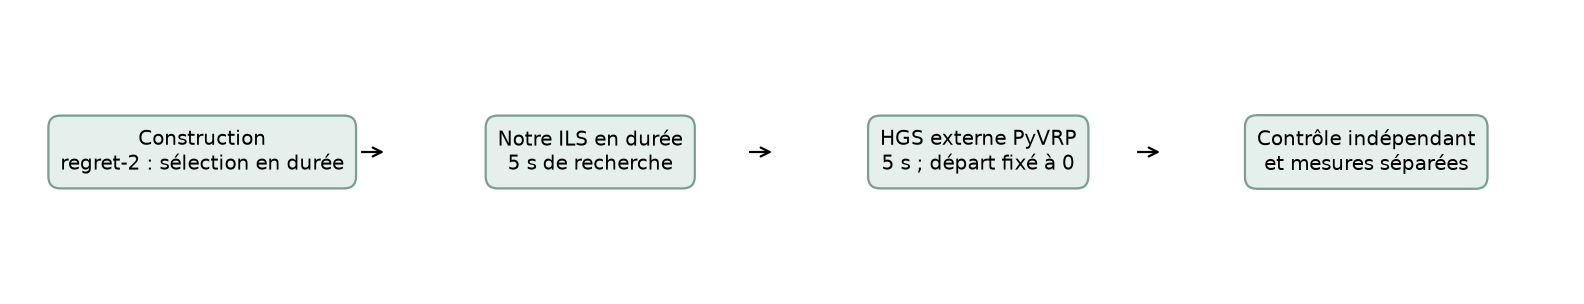

In [5]:
display(Image(filename=str(ROOT/'livraison/duree_figures/pipeline.png')))

**Lecture du schéma.** Les flèches indiquent le transfert d'une solution entre quatre étapes. Le constructeur produit d'abord une solution réalisable et sélectionne ses départs selon leur durée complète. Notre ILS dispose ensuite de cinq secondes pour la modifier. Le HGS externe de PyVRP reçoit la meilleure solution et dispose de cinq secondes supplémentaires. Le contrôle final recalcule la couverture des clients, les charges, les horaires et la durée indépendamment du moteur de recherche.

**Intérêt et lien avec les expériences.** Le schéma situe notre contribution et celle de la bibliothèque externe, et explique le partage du budget du profil mesuré. Les dix secondes concernent la recherche : construction, préparation et contrôle s'ajoutent au temps total. Les tableaux et courbes suivants évaluent ce pipeline précis ; ils ne constituent pas une mesure des variantes expérimentales testées ultérieurement.

### 4.4. Modifications et vérifications

| Modification | Motif | Vérification |
|---|---|---|
| Objectif PLNE sur les retours $R_k$ | Minimiser la durée cumulée | Concordance de dix optimums avec une énumération indépendante |
| Évaluateur temporel des mouvements | Inclure attente, service et retour | Deux ordres de même trajet mais de durées 34/28 sont distingués |
| Sélection initiale et archive en durée | Éviter une acceptation restée en distance | Coûts confrontés à `verify`, archive non dégradée |
| HGS : coût durée et départ fixé | Aligner le moteur externe sur le modèle | Test d’une attente obligatoire que le départ ne peut masquer |
| Nouvelles références temporelles | Éviter de renommer les gaps distance | Tournées de référence réévaluées, qualification explicite |
| Nouvelle campagne et statistique descriptive | Mesurer l’effet réel de la méthode | Données individuelles, graines, sources figées et effectifs conservés |
| Simplification de C7 pour l'objectif durée | Retirer uniquement une borne supérieure redondante | Dix optimums exacts conservés ; fermeture du dépôt maintenue |
| Audit exhaustif des écarts temporels | Contrôler le seuil par essai et par instance | 646 solutions et 356 témoins revalidés ; dépassements listés en section 6.7 |
| Constructions alternatives et intensification locale | Réduire les mauvaises durées de départ | Essais exploratoires séparés, solutions revalidées et régressions conservées |
| Carte, horaires et temps d'exécution | Relier représentation, objectif et coût de calcul | Figures issues des mêmes résultats enregistrés et commentées individuellement |
| Cache local des voisinages | Supprimer les tris répétés sur une instance immuable | Listes identiques à PyVRP et coûts identiques sur douze paires ; CPU mesuré en section 6.12 |
| Étude multiprocessus | Distinguer délai de réponse et CPU consommé | Un, deux et quatre processus ; parent et workers comptés, démarrage publié |

L’implémentation propre de l’ILS, les adaptateurs et la vérification sont dans le projet ; le moteur génétique externe appartient à PyVRP. Les commentaires du code expliquent les fonctions et les points sensibles.

### 4.5. Suivre les données dans les fonctions réelles

Une solution est une liste de listes : `[[1, 2]]` représente dépôt → 1 → 2 → dépôt. `encode` la convertit en une matrice de clients et un tableau de longueurs pour les boucles compilées ; `decode` reconstruit la liste. Ces deux représentations décrivent les mêmes tournées, sans ajouter le dépôt dans les listes de clients.

**Construire (`construct`).** L'entrée est une instance et une graine ; la sortie contient les tournées retenues et le temps de construction. Les insertions utilisent les trajets pour guider la construction, mais les solutions complètes sont comparées selon leur durée indépendante, attentes comprises. L'extrait suivant est la fonction réelle de `algo/duration.py`.

```python
def construct(ins, seed, attempts=12):
    """Sélectionne en durée le meilleur départ réalisable parmi les insertions.

    Les surcoûts de trajet guident regret-2, mais le choix entre les solutions
    complètes utilise leur véritable durée, avec toutes les attentes.
    """
    started=time.perf_counter();rng=random.Random(seed)
    best=None;value=math.inf
    for attempt in range(attempts):
        matrix,lengths=encode([],ins)
        valid=kernels.repair_fast(matrix,lengths,len(lengths)-1,*arrays(ins),2,
                                  0. if attempt==0 else .2,rng.randrange(2**31))
        if valid:
            routes=decode(matrix,lengths);checked=verify(routes,ins)
            if checked['valid'] and checked['duration']<value:
                best,value=routes,checked['duration']
    return best,dict(seconds=time.perf_counter()-started,attempts=attempts,
                     duration=value/10 if best is not None else None)
```

**Enchaîner les recherches (`solve`).** À partir de la solution construite, cette partie réelle de la fonction répartit le budget et transmet les tournées de l'ILS au HGS externe. Elle n'utilise pas le plan de référence pour chercher une solution.

```python
    own_seconds = cfg.seconds * cfg.ils_fraction if cfg.method == 'hybrid' else cfg.seconds
    first = search(ins, initial, own_seconds, cfg.seed,
                   'sa' if cfg.method == 'sa' else 'ils', cfg.tolerance)
    components = [first]
    if cfg.method == 'hybrid':
        from .hgs_tuning import solve as hgs
        components.append(hgs(ins, cfg.seconds-own_seconds, cfg.seed+10000,
                              first['routes'], cfg.neighbors, objective='duration'))
```

**Accepter un mouvement (`walk`).** Après avoir recalculé les durées et vérifié les tournées touchées, `ca` et `cb` sont leurs nouvelles durées, et `costs` contient les anciennes. Le delta est donc la variation de durée complète, et non une simple économie de deux arcs. En mode perturbation, une hausse réalisable est possible ; en mode recherche, une baisse est acceptée, et le recuit peut accepter une hausse selon sa température. Extrait réel de `algo/duration_moves.py` :

```python
        delta = ca - costs[a] + (cb - costs[b] if b != a else 0.0)
        valid += 1
        # Une dégradation peut aider à sortir d’un optimum local, mais jamais au prix de la faisabilité.
        take = mode == 0 or delta <= 1e-9
        if not take and mode == 1:
            take = np.random.random() < math.exp(
                -min(745.0, delta / max(temperature, 1e-12))
            )
        if not take:
            if diagnostics is not None:
                diagnostics[5] += 1
            continue
```

**Exemple avant/après.** Dans l'exemple des deux clients, remplacer `[1, 2]` par `[2, 1]` fait passer la durée de 34 à 28 : le delta affiché est −6 (−60 dans les unités internes). Le trajet reste 18, les services restent 9 et l'attente passe de 7 à 1. La solution candidate doit toujours respecter les fenêtres et la capacité avant son acceptation. Un changement d'ordre n'est donc utile que si son évaluation temporelle complète le confirme.

**Lien avec la version précédente.** Les principes construction → perturbation → intensification → validation sont conservés. En revanche, la campagne en durée a mesuré une descente échantillonnée plus simple et un budget de dix secondes. Les performances de l'ancien moteur avancé en distance ne constituent pas une mesure du même moteur en durée. Restaurer ses mécanismes exige d'adapter aussi les filtres, les coûts et les acceptations ; renommer uniquement la fonction objectif ne suffirait pas.

## 5. Protocole et références des benchmarks en durée

Nous utilisons les 56 Solomon à 100 clients et les 300 Gehring–Homberger de 200, 400, 600, 800 et 1 000 clients : **356 instances**. Les matrices de temps conservent la convention des fichiers DIMACS : arcs euclidiens tronqués à une décimale, horaires et services à la même échelle. Les durées sont exprimées en unités du benchmark, pas en minutes réelles démontrées.

La campagne de couverture comporte **472 pipelines hybrides** : une graine sur toutes les instances, une seconde à 100/1 000 clients. Le lot de stabilité compare ILS, recuit et hybride sur C101, R202 et R2_10_8, avec **20 graines par couple instance/méthode**, soit 180 résolutions. Six résolutions hybrides appartiennent déjà à la couverture : le total distinct est **646**, pas 652. Toutes sont exécutées pour l’objectif durée.

Chaque méthode dispose de dix secondes de recherche. Construction et préparation externe sont comptées en plus ; la compilation est préchauffée séparément. Les essais sont répartis sur six processus à une affinité CPU enregistrée, avec les bibliothèques de calcul limitées à un thread. Graines, ordre, versions et sources exécutées sont figés dans le protocole.

Les trois cas répétés représentent un cas groupé, un cas aléatoire et une grande instance historiquement difficile. Ce choix ne rend pas le lot représentatif de toutes les situations. Les méthodes reçoivent la même construction pour une même instance et graine ; celle-ci est effectivement recalculée et facturée dans chaque résolution.

### 5.1. Ce que signifie la référence

Les fichiers `.sol` DIMACS donnent des tournées de référence sélectionnées pour la **distance**. Nous recalculons leur durée, avec les mêmes services, fenêtres et départs à zéro. Ce plan est un **témoin réalisable**, dont l’optimalité en durée n’est pas établie. Son utilisation n’introduit pas de connaissance dans le solveur : il est lu après la résolution.

L’écart au témoin est :

$$E=100\frac{T_{\mathrm{obtenu}}-T_{\mathrm{témoin}}}{T_{\mathrm{témoin}}}.$$

Un écart négatif signifie que la solution est plus courte en durée que ce témoin ; cela ne signifie pas qu’un optimum a été battu. Nous ne présentons pas cet indicateur comme un gap à une BKS temporelle. Les anciens pourcentages calculés en distance ne qualifient pas l’objectif actuel.

### 5.2. Borne inférieure et véritable gap

Pour les petits cas, une preuve d’optimalité permet un véritable gap $100(T/T^*-1)$. Pour les grandes instances, nous utilisons aussi une borne simple :

$$L=\sum_i s_i+\operatorname{MST}(G,c)\le T^*.$$

L’union des tournées rejoint le dépôt et tous les clients ; son temps de trajet est au moins celui d’un arbre couvrant minimal. L’attente est non négative et les services sont obligatoires. Ainsi $100(T/L-1)$ borne supérieurement le gap à l’optimum, mais peut être très pessimiste. Il ne s’agit pas d’une BKS. Les trois notions — optimum prouvé, borne inférieure et plan témoin — restent séparées dans les tableaux.

### Périmètre final et compatibilité des références

Les hypothèses retenues sont $c_{ij}=c_{ji}$, sans dépendance à l’heure,
départs à zéro et $\min\sum_k R_k$. Un graphe orienté décrit les décisions
de visite même si ses temps de parcours sont symétriques. Les départs et
retours virtuels représentent le même dépôt physique.

Les campagnes historiques restent conservées. Leurs écarts aux plans distance
réévalués sont distincts du nouveau pilote à référence OR-Tools indépendante.
La compatibilité complète des optima Phonin n'est pas établie : nous ne leur
attribuons pas de gaps certifiés. Les variantes à trajets variables et départs
optimisés sont archivées hors du modèle principal.

La vérification des références est décrite dans
`docs/COMPATIBILITE_REFERENCES_STATIQUES.md`. Les résultats négatifs, nuls,
supérieurs à 6 % et les échecs restent visibles ; aucun pourcentage n'est plafonné.


## 6. Résultats et statistique descriptive

### 6.1. Couverture, qualité temporelle et temps de calcul

### Comparaisons validées : statuts et statistiques conditionnelles

Une référence heuristique peut être dépassée ou égalée sans qu'un optimum
temporel ait été démontré. Ces cas sont affichés par statut. Les coûts réels,
les anciennes comparaisons signées et leur réévaluation indépendante restent
dans `AUDIT_GAPS_FINAL.md` et `results/presentation_status/`.

L'audit a recalculé **1321 comparaisons chiffrées** : **947 références dépassées,
129 égalités et 245 écarts positifs**, sans anomalie de coût ni faisabilité.
Il s'agit d'enregistrements, comprenant des vues d'archive et plusieurs
références d'un même essai, pas d'un nouveau nombre de résolutions.

Les moyennes et médianes ci-dessous sont **conditionnelles aux seuls écarts
positifs comparables**. La colonne Positifs en donne le dénominateur ; les
autres statuts restent explicitement comptés. Elles ne sont jamais présentées
comme des moyennes sur toutes les instances. Les valeurs supérieures au seuil
de six pour cent sont conservées. Aucun coût, contrainte, référence ou réglage
de l'algorithme n'a été détérioré pour changer le signe d'un pourcentage.

**Campagne initiale — 472 essais de couverture.**

|    n |   Essais |   Positifs |   References_depassees |   References_egalees |   Non_comparables | Moyenne_positive_pct   | Mediane_positive_pct   |   Positifs_superieurs_6 |
|-----:|---------:|-----------:|-----------------------:|---------------------:|------------------:|:-----------------------|:-----------------------|------------------------:|
|  100 |      112 |          0 |                     88 |                   24 |                 0 | Non applicable         | Non applicable         |                       0 |
|  200 |       60 |          0 |                     60 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
|  400 |       60 |         11 |                     49 |                    0 |                 0 | 1.0034                 | 0.7889                 |                       0 |
|  600 |       60 |         18 |                     42 |                    0 |                 0 | 4.1692                 | 3.2759                 |                       3 |
|  800 |       60 |         19 |                     41 |                    0 |                 0 | 5.9762                 | 4.8539                 |                       6 |
| 1000 |      120 |         42 |                     78 |                    0 |                 0 | 9.6411                 | 9.3202                 |                      29 |

**Archive des plans sélectionnés — budgets différents, pas campagne uniforme.**

|    n |   Essais |   Positifs |   References_depassees |   References_egalees |   Non_comparables | Moyenne_positive_pct   | Mediane_positive_pct   |   Positifs_superieurs_6 |
|-----:|---------:|-----------:|-----------------------:|---------------------:|------------------:|:-----------------------|:-----------------------|------------------------:|
|  100 |      112 |          0 |                     88 |                   24 |                 0 | Non applicable         | Non applicable         |                       0 |
|  200 |       60 |          0 |                     60 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
|  400 |       60 |         11 |                     49 |                    0 |                 0 | 1.0034                 | 0.7889                 |                       0 |
|  600 |       60 |         16 |                     44 |                    0 |                 0 | 2.9670                 | 2.6530                 |                       0 |
|  800 |       60 |         19 |                     41 |                    0 |                 0 | 3.0979                 | 3.1898                 |                       0 |
| 1000 |      120 |         38 |                     82 |                    0 |                 0 | 2.6492                 | 2.5722                 |                       0 |

**Nouveaux pilotes — comparaison au solveur indépendant du même lot.**

| campaign               | method               |   Essais |   Positifs |   References_depassees |   References_egalees |   Non_comparables | Moyenne_positive_pct   | Mediane_positive_pct   |   Positifs_superieurs_6 |
|:-----------------------|:---------------------|---------:|-----------:|-----------------------:|---------------------:|------------------:|:-----------------------|:-----------------------|------------------------:|
| confirmation_ils_v2    | ils                  |        8 |          4 |                      2 |                    2 |                 0 | 9.3990                 | 9.8381                 |                       2 |
| confirmation_ils_v2    | refined              |        8 |          4 |                      4 |                    0 |                 0 | 2.7700                 | 1.7680                 |                       1 |
| confirmation_ils_v2    | refined_ils          |        8 |          1 |                      5 |                    2 |                 0 | 1.7570                 | 1.7570                 |                       0 |
| couverture_progressive | construction         |        7 |          6 |                      1 |                    0 |                 0 | 14.0422                | 10.7670                |                       4 |
| couverture_progressive | hybrid               |        7 |          2 |                      4 |                    1 |                 0 | 14.6550                | 14.6550                |                       2 |
| couverture_progressive | ils                  |        7 |          5 |                      1 |                    1 |                 0 | 6.5482                 | 4.8451                 |                       2 |
| couverture_progressive | pyvrp                |        7 |          3 |                      1 |                    1 |                 2 | 2.4152                 | 0.9649                 |                       0 |
| couverture_progressive | refined              |        7 |          2 |                      5 |                    0 |                 0 | 4.1377                 | 4.1377                 |                       1 |
| couverture_progressive | refined_ils          |        7 |          2 |                      5 |                    0 |                 0 | 2.6351                 | 2.6351                 |                       0 |
| couverture_progressive | refined_no_partition |        7 |          2 |                      5 |                    0 |                 0 | 4.1377                 | 4.1377                 |                       1 |
| couverture_progressive | sa                   |        7 |          3 |                      4 |                    0 |                 0 | 1.7087                 | 2.1286                 |                       0 |
| pilote25               | construction         |        3 |          3 |                      0 |                    0 |                 0 | 27.2941                | 8.4925                 |                       2 |
| pilote25               | hybrid               |        3 |          0 |                      0 |                    3 |                 0 | Non applicable         | Non applicable         |                       0 |
| pilote25               | ils                  |        3 |          0 |                      0 |                    3 |                 0 | Non applicable         | Non applicable         |                       0 |
| pilote25               | pyvrp                |        3 |          0 |                      0 |                    3 |                 0 | Non applicable         | Non applicable         |                       0 |
| pilote25               | refined              |        3 |          1 |                      0 |                    2 |                 0 | 0.9114                 | 0.9114                 |                       0 |
| pilote25               | refined_no_partition |        3 |          1 |                      0 |                    2 |                 0 | 0.9114                 | 0.9114                 |                       0 |
| pilote25               | sa                   |        3 |          0 |                      0 |                    3 |                 0 | Non applicable         | Non applicable         |                       0 |

Les autres tableaux signalent « voir répartition par statut » lorsque leur
ancienne colonne était une moyenne signée mélangeant les statuts. Cette
colonne n'est pas rebaptisée moyenne positive. Les valeurs originales sont
conservées dans les CSV techniques. Une égalité à une référence heuristique
n'est jamais étiquetée « Optimum atteint » ; ce statut reste réservé aux
petits cas exacts avec preuve vérifiée. Une contradiction face à un optimum
certifié bloque la validation. La borne inférieure fournit une majoration
du gap, pas sa valeur exacte. Le seuil académique n'est pas certifié pour
tout le catalogue par ces références heuristiques.


Les 646 résolutions historiques sont réalisables. Le tableau suivant
compte les 472 essais de couverture, séparément des répétitions. Les moyennes
et médianes portent uniquement sur les écarts strictement positifs ; leurs
effectifs sont affichés. Les références dépassées, égalées et les comparaisons
indisponibles restent comptées. Ces moyennes ne représentent pas tous les essais.

|    n |   Essais |   Positifs |   References_depassees |   References_egalees |   Non_comparables | Moyenne_positive_pct   | Mediane_positive_pct   |   Positifs_superieurs_6 |
|-----:|---------:|-----------:|-----------------------:|---------------------:|------------------:|:-----------------------|:-----------------------|------------------------:|
|  100 |      112 |          0 |                     88 |                   24 |                 0 | Non applicable         | Non applicable         |                       0 |
|  200 |       60 |          0 |                     60 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
|  400 |       60 |         11 |                     49 |                    0 |                 0 | 1.0034                 | 0.7889                 |                       0 |
|  600 |       60 |         18 |                     42 |                    0 |                 0 | 4.1692                 | 3.2759                 |                       3 |
|  800 |       60 |         19 |                     41 |                    0 |                 0 | 5.9762                 | 4.8539                 |                       6 |
| 1000 |      120 |         42 |                     78 |                    0 |                 0 | 9.6411                 | 9.3202                 |                      29 |

Les moyennes favorables ne suppriment pas les cas difficiles. Voici les six instances dont la durée moyenne dépasse le plus celle du plan témoin ; elles restent dans tous les tableaux de leur périmètre.

| instance | n | mean_duration | reference_duration | Moyenne positive conditionnelle — mean_delta_reference_pct / statut | mean_calculation_s |
| --- | --- | --- | --- | --- | --- |
| C1_10_6 | 1000 | 167151,950 | 133754,700 | 24.9690 % (positifs 2/2) | 14,510 |
| C1_8_1 | 800 | 118110,800 | 97704,100 | 20.8862 % (positifs 1/1) | 12,607 |
| C2_10_7 | 1000 | 128157,000 | 106940,000 | 19.8401 % (positifs 2/2) | 14,004 |
| C2_10_2 | 1000 | 126639,150 | 109395,800 | 15.7624 % (positifs 2/2) | 14,420 |
| C1_6_1 | 600 | 78992,900 | 68564,200 | 15.2101 % (positifs 1/1) | 11,290 |
| C2_10_1 | 1000 | 122295,950 | 106856,600 | 14.4487 % (positifs 2/2) | 13,862 |


Le pire essai individuel est C1_10_6, graine 4102 : **+26.767 %** au témoin. Il ne doit pas être confondu avec une moyenne d’instance.

Ces écarts positifs montrent une marge d’amélioration au budget de dix secondes. Ils ne sont ni cachés par la moyenne générale ni transformés en zéros. Le témoin reste une solution réalisable et non un optimum démontré en durée.

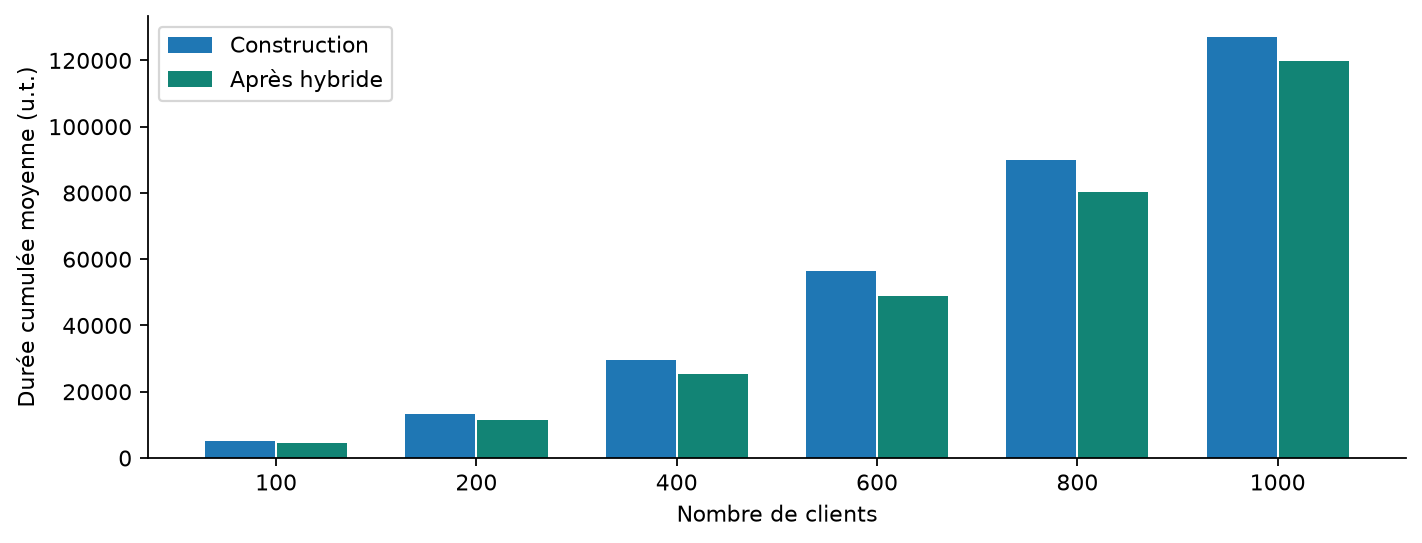

In [6]:
display(Image(filename=str(ROOT/'livraison/duree_figures/avant_apres.png')))

**Lecture du graphique.** Pour chaque taille, la barre bleue donne la durée moyenne après construction et la barre verte la durée après recherche hybride, sur les mêmes essais de couverture. L'axe vertical est exprimé en unités de durée des tournées, et non en secondes de calcul. Une barre verte plus basse indique une amélioration par rapport au départ construit. À 100 et 1 000 clients, les deux graines par instance participent à cette moyenne ; les autres tailles ont une graine par instance.

**Intérêt et continuité.** Après avoir décrit les étapes de l'algorithme, nous vérifions ici qu'elles améliorent effectivement les solutions initiales. Ce graphique ne compare pas encore la qualité à une référence et ne montre pas la dispersion entre essais. La décomposition suivante précise ce que contient la durée ; les boîtes et histogrammes complètent ensuite la lecture des moyennes.

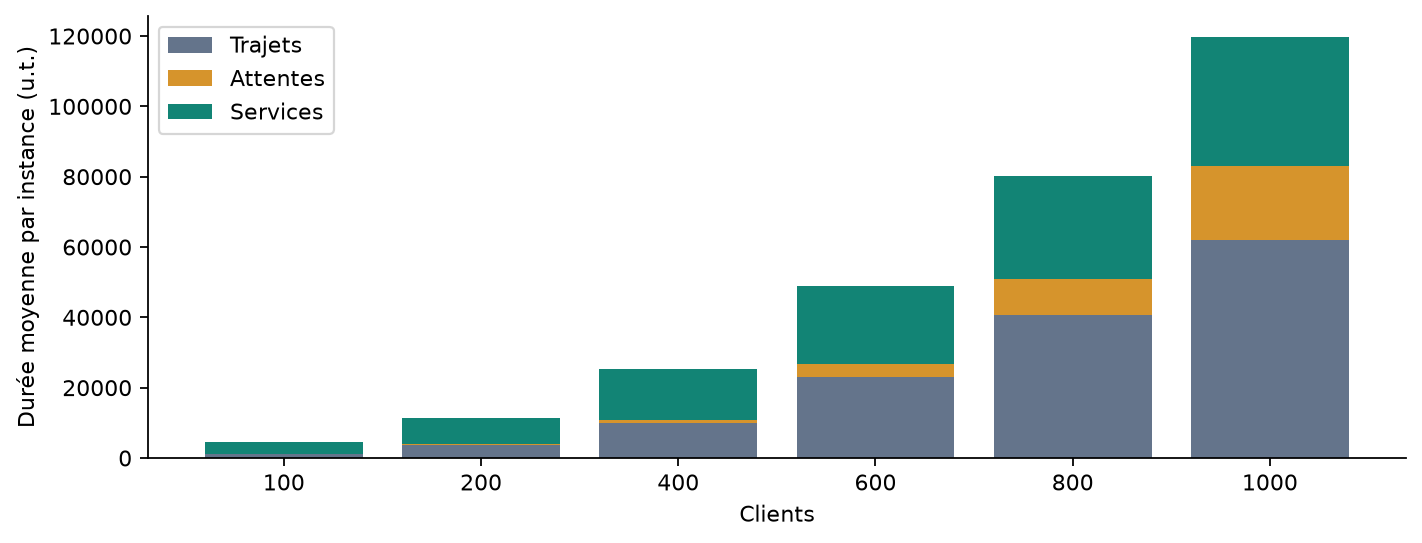

In [7]:
display(Image(filename=str(ROOT/'livraison/duree_figures/composition.png')))

**Lecture du graphique.** Chaque barre empilée représente la durée finale moyenne d'une taille, avec une moyenne calculée d'abord par instance. Le gris mesure les trajets, l'orange les attentes et le vert les services. Leur somme est la durée totale représentée par la hauteur de la barre. Les services peuvent différer entre instances, mais leur somme est fixe lorsqu'on compare deux solutions réalisables d'une même instance, puisque chaque client est servi exactement une fois.

**Intérêt et continuité.** Cette figure donne un sens opérationnel aux durées du graphique précédent. Pour améliorer une instance sans changer ses données, la recherche doit réduire les trajets et les attentes ; elle ne peut pas raccourcir arbitrairement les services. Cette distinction aide aussi à interpréter les pourcentages : une part fixe importante de services peut réduire un écart relatif sans démontrer que les trajets sont proches de leur meilleur niveau.

### 6.2. Population, variables et données tabulaires

Une ligne d’essai représente une instance, une graine, une méthode et un budget. Le nom de l’instance et la méthode sont qualitatifs ; le nombre de clients est discret ; durée, attente et temps de calcul sont quantitatifs ; la faisabilité est booléenne. Une graine sert à identifier une exécution, pas à expliquer causalement sa performance.

Les cases manquantes des indicateurs de qualité d’un échec ne valent jamais zéro. La colonne d’erreur est normalement vide pour une réussite. Nous contrôlons les colonnes indispensables sur les essais réalisables avant de calculer les statistiques.

In [8]:
cols=['instance','seed','method','n','valid','duration','reference_duration','total_s']
display(runs[cols].head())
display(runs[cols].dtypes.to_frame('type'))
display(runs[cols].isna().sum().to_frame('manquants'))
assert runs.loc[runs.valid,['duration','reference_duration','total_s']].notna().all().all()
# Synthèse de 356 moyennes d’instance, avec même poids par instance.
z=cases[['mean_duration','mean_waiting','mean_calculation_s']]
auto=z.describe()
auto.loc['std']=z.std(ddof=0)  # Harmoniser la convention descriptive N.
display(auto)

,instance,seed,method,n,valid,duration,reference_duration,total_s
0,C101,4101,hybrid,100,True,9827.3,9827.3,10.034964
1,C101,4101,ils,100,True,9827.3,9827.3,10.028413
2,C101,4101,sa,100,True,9961.0,9827.3,10.030156
3,C101,4102,hybrid,100,True,9827.3,9827.3,10.034789
4,C101,4102,ils,100,True,9827.3,9827.3,10.027946


,type
instance,object
seed,int64
method,object
n,int64
valid,bool
duration,float64
reference_duration,float64
total_s,float64


,manquants
instance,0
seed,0
method,0
n,0
valid,0
duration,0
reference_duration,0
total_s,0


,mean_duration,mean_waiting,mean_calculation_s
count,356.000000,356.000000,356.000000
mean,48850.332865,6115.651966,11.511504
std,42863.942854,12202.627038,1.537882
min,1744.850000,0.000000,10.034673
25%,9827.300000,36.675000,10.143297
50%,37739.650000,495.700000,11.110476
75%,79917.875000,5144.525000,12.606825
max,167151.950000,70033.650000,15.225576


### 6.3. Position, dispersion et quantiles

Pour N valeurs observées, la moyenne est $\bar x=N^{-1}\sum x_i$. La médiane partage la série ordonnée en deux moitiés ; elle est moins sensible que la moyenne aux valeurs élevées. Le mode est une valeur la plus fréquente ; pour une série continue sans répétition, il peut ne pas y avoir de mode distinct utile.

Nous employons la variance descriptive $v=N^{-1}\sum(x_i-\bar x)^2$ et l’écart-type $\sigma=\sqrt v$, avec `ddof=0`. La variance corrigée divisée par N−1 répondrait à une autre convention et n’est pas mélangée ici. L’étendue vaut maximum moins minimum ; l’IQR vaut $Q_3-Q_1$. Les quantiles sont calculés par interpolation linéaire Pandas, convention annoncée pour rendre les résultats reproductibles.

Les tableaux suivants portent sur les **vingt répétitions d’une même instance et méthode**. Les colonnes détaillées, y compris les quantiles 2,5 %, 10 %, 30 %, 70 %, 90 % et 97,5 %, sont conservées en CSV.

| instance   | method          |   n | mean      | median    | std      | minimum   | q0.25     | q0.75     | maximum    | iqr      |
|:-----------|:----------------|----:|:----------|:----------|:---------|:----------|:----------|:----------|:-----------|:---------|
| C101       | ILS durée + HGS |  20 | 9827,300  | 9827,300  | 0,000    | 9827,300  | 9827,300  | 9827,300  | 9827,300   | 0,000    |
| C101       | ILS durée       |  20 | 9854,040  | 9827,300  | 53,480   | 9827,300  | 9827,300  | 9827,300  | 9961,000   | 0,000    |
| C101       | Recuit durée    |  20 | 9960,965  | 9915,800  | 140,925  | 9827,300  | 9827,300  | 10073,600 | 10195,900  | 246,300  |
| R202       | ILS durée + HGS |  20 | 2377,305  | 2376,750  | 10,907   | 2361,400  | 2367,875  | 2386,900  | 2399,800   | 19,025   |
| R202       | ILS durée       |  20 | 2651,955  | 2659,650  | 138,383  | 2407,500  | 2605,375  | 2739,850  | 2865,600   | 134,475  |
| R202       | Recuit durée    |  20 | 2488,380  | 2476,100  | 51,308   | 2409,000  | 2474,500  | 2488,925  | 2697,700   | 14,425   |
| R2_10_8    | ILS durée + HGS |  20 | 87594,075 | 85859,000 | 5803,493 | 80273,000 | 83718,000 | 89652,825 | 100546,600 | 5934,825 |
| R2_10_8    | ILS durée       |  20 | 93806,260 | 93459,750 | 1806,187 | 90535,300 | 92558,050 | 95147,150 | 98220,100  | 2589,100 |
| R2_10_8    | Recuit durée    |  20 | 88610,995 | 88195,800 | 2647,555 | 82803,900 | 86916,400 | 90490,425 | 95106,800  | 3574,025 |

Sur C101, les vingt résultats hybrides ont une moyenne de 9827.300 et une médiane de 9827.300 u.t., avec un écart-type de 0.000. Cette stabilité observée ne garantit pas tous les essais futurs. Sur R2_10_8, la moyenne vaut 87594.075 contre une médiane de 85859.000 u.t. ; l’histogramme permet de lire l’influence des durées les plus élevées.

In [9]:
# Une fiche complète, verticale pour garder la lecture lisible.
fiche=descriptive.query("instance == 'R2_10_8' and method == 'hybrid' and metric == 'duration'")
display(fiche.drop(columns=['instance','method','metric']).T.rename(columns={fiche.index[0]:'valeur'}))
x=repetitions.query("instance == 'R2_10_8' and method == 'hybrid'").duration
print('variance N :',x.var(ddof=0),'écart-type :',x.std(ddof=0))
display(x.quantile([.025,.1,.3,.7,.9,.975]).to_frame('durée'))

,valeur
n,20
mean,87594.075
median,85859.0
mode,aucun mode distinct
variance,33680525.590875
std,5803.492534
minimum,80273.0
maximum,100546.6
range,20273.6
iqr,5934.825


variance N : 33680525.59087499 écart-type : 5803.492533886383


,durée
0.025,80666.4425
0.100,81912.3800
0.300,83807.2100
0.700,87989.6000
0.900,97712.5000
0.975,99279.9175


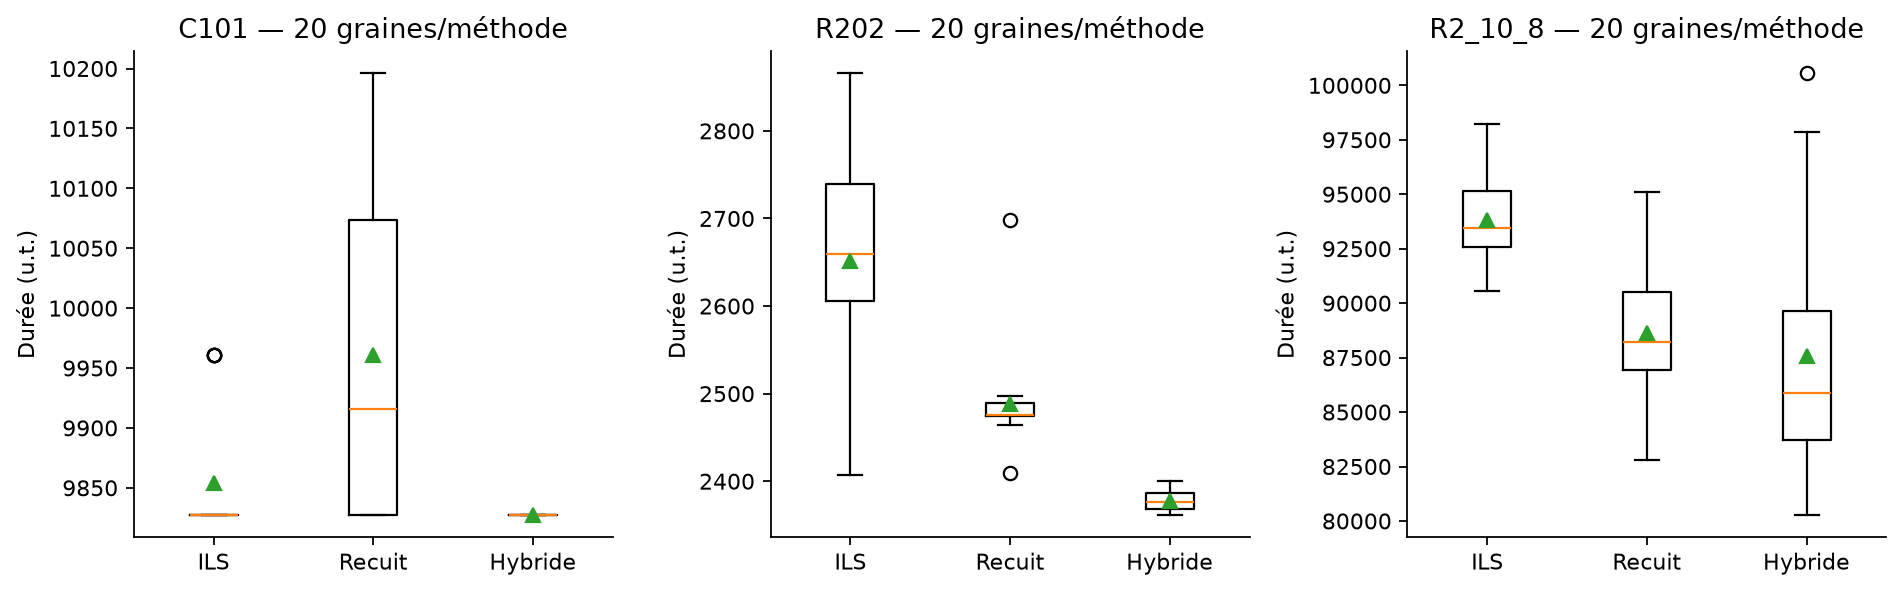

In [10]:
display(Image(filename=str(ROOT/'livraison/duree_figures/repetitions.png')))

**Lecture des boîtes.** Chaque panneau correspond à une instance, et chaque boîte résume vingt graines d'une même méthode au même budget de recherche. La boîte s'étend de Q1 à Q3, le trait orange est la médiane et le triangle vert la moyenne. Les moustaches suivent la règle de 1,5 IQR ; les points extérieurs restent de vrais résultats conservés dans l'analyse. Une boîte plus basse indique de meilleures durées ; une boîte plus courte indique une moindre dispersion centrale. Les échelles verticales diffèrent entre panneaux.

**Interprétation et suite.** Sur C101, les résultats hybrides sont identiques dans ce lot. Sur R2_10_8, l'hybride obtient une moyenne plus basse mais une dispersion plus forte que l'ILS : qualité moyenne et régularité sont donc deux critères distincts. Les histogrammes suivants montrent où se concentrent les observations que les boîtes résument.

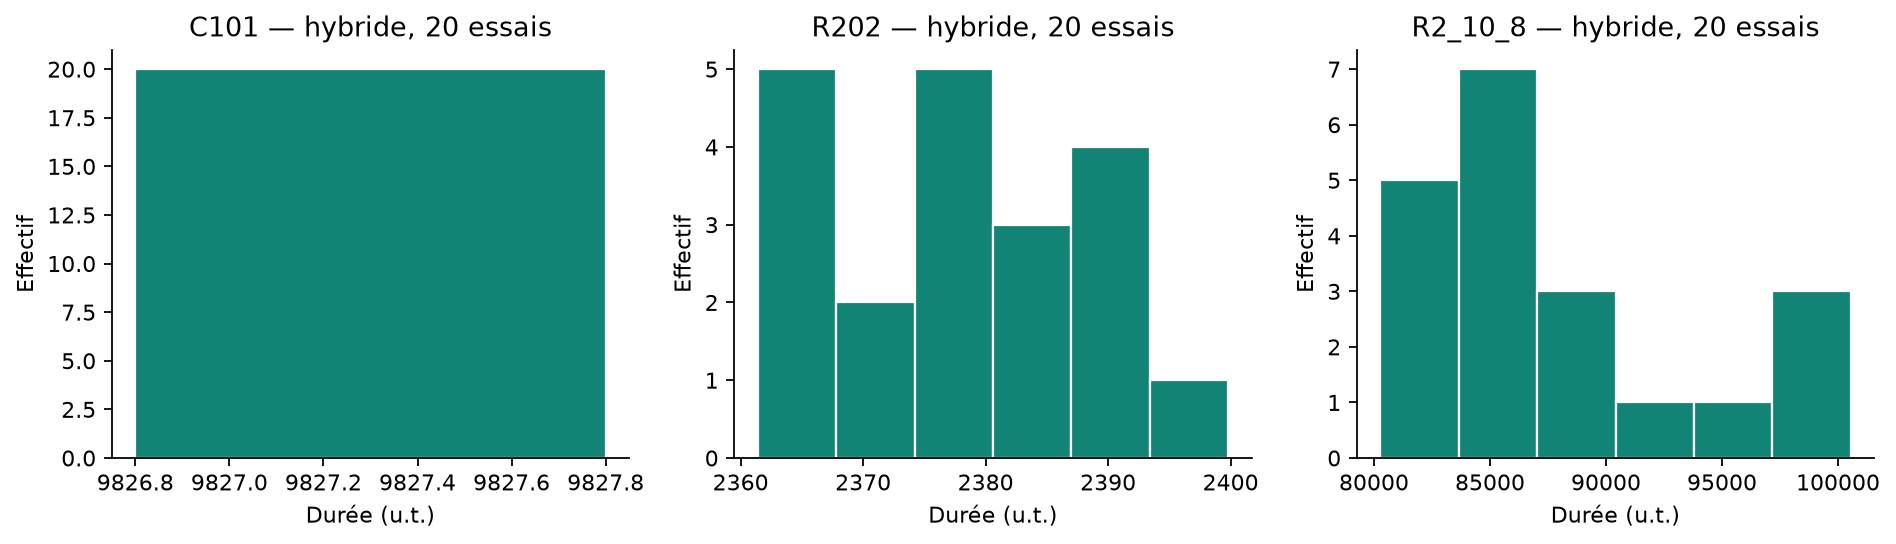

In [11]:
display(Image(filename=str(ROOT/'livraison/duree_figures/histogrammes_repetitions.png')))

**Lecture des histogrammes.** Ces trois panneaux reprennent uniquement les vingt essais hybrides de chaque cas. L'axe horizontal porte la durée finale et la hauteur d'une barre indique le nombre d'essais dans une classe de durées. Les classes sont choisies séparément pour chaque panneau : les hauteurs ne servent donc pas à comparer directement la densité des trois instances. Pour C101, l'unique barre contient vingt valeurs identiques ; sa largeur graphique ne représente pas une dispersion réelle.

**Intérêt et continuité.** L'histogramme complète la boîte en montrant la répartition des résultats. Sur R2_10_8, quelques durées élevées tirent la moyenne au-dessus de la médiane. Cette lecture explique pourquoi nous rapportons aussi les quantiles et les valeurs extrêmes. Elle concerne la variabilité des graines sur un cas ; les figures suivantes changent d'échelle pour examiner des instances différentes.

La boîte contient les observations entre Q1 et Q3 et son trait central est la médiane ; le marqueur représente la moyenne. Les moustaches atteignent les dernières observations dans les bornes Q1−1,5 IQR et Q3+1,5 IQR. Les autres points sont potentiellement atypiques : ils ne sont pas supprimés.

Une moyenne supérieure à la médiane peut signaler l’influence de grandes valeurs, mais l’interprétation doit être confrontée à l’histogramme. Une série constante n’a pas une dispersion normale non dégénérée. Avec vingt valeurs et des contraintes produisant des plateaux, nous ne supposons pas automatiquement une loi normale et n’appliquons pas les probabilités d’une gaussienne sans justification.

Les graphiques globaux suivants représentent les moyennes de **356 instances différentes**. Ils décrivent l’hétérogénéité du catalogue et ne remplacent pas l’étude entre graines d’un même cas.

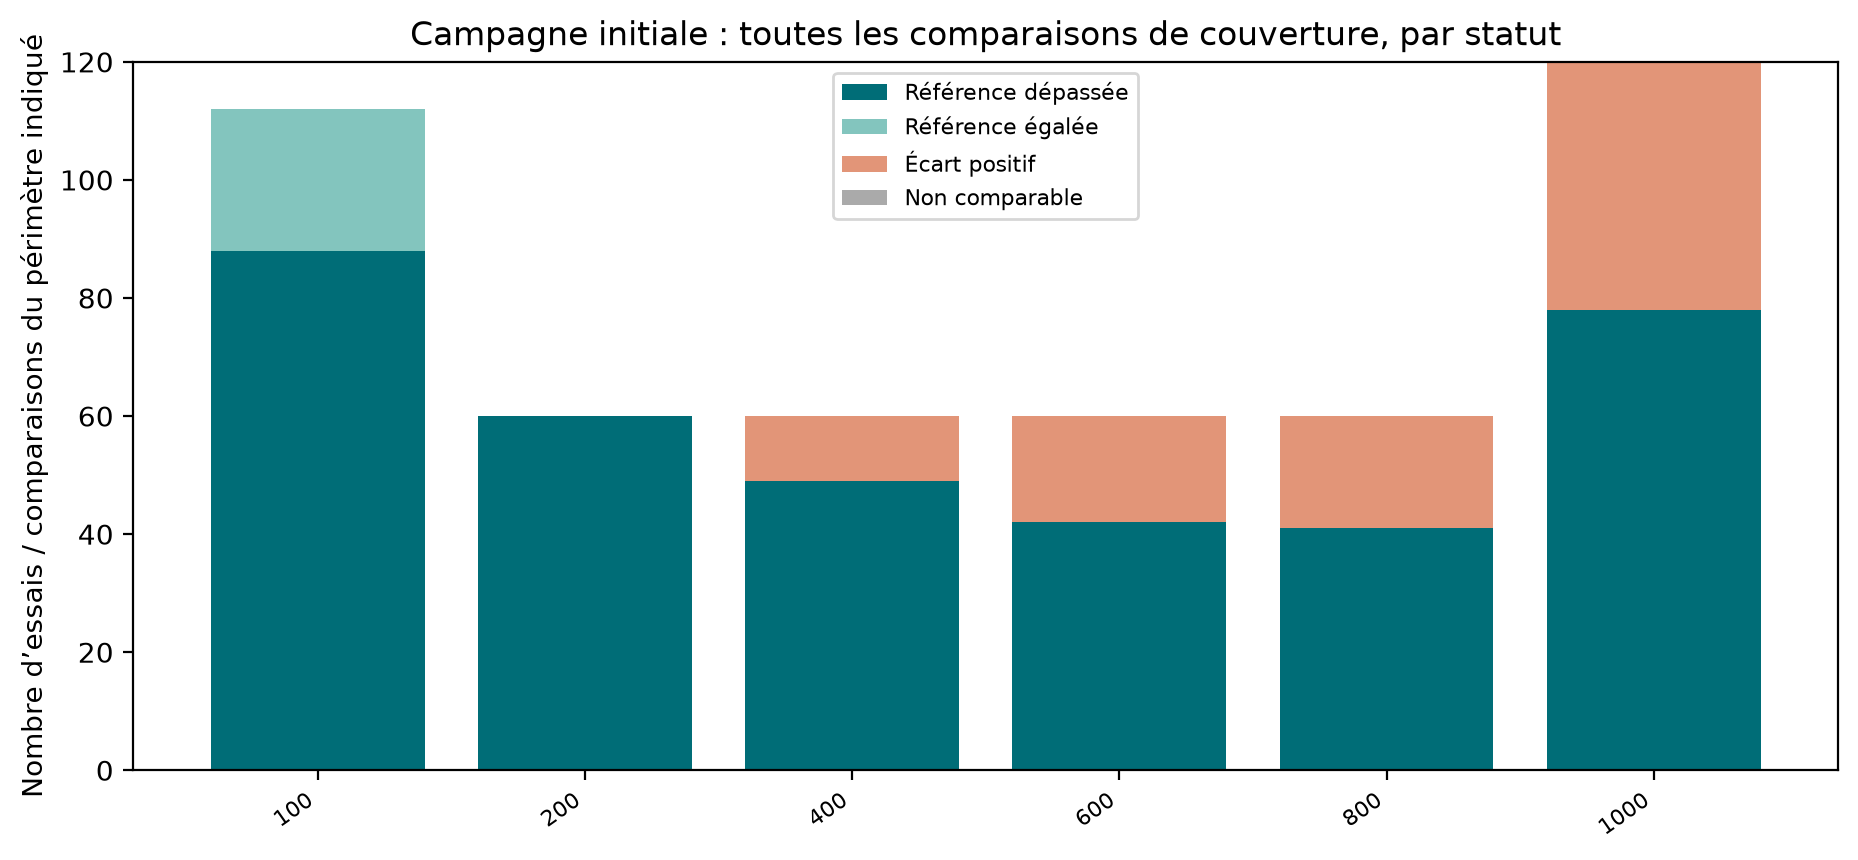

In [12]:
display(Image(filename=str(ROOT/'livraison/duree_figures/presentation_statuts_taille.png')))

**Lecture des statuts par taille.** Chaque barre compte tous les essais
de couverture de cette taille. Les couleurs distinguent les références dépassées,
les références égalées et les écarts positifs. Aucun optimum n'est déduit d'une
égalité avec un témoin heuristique. Les effectifs et les moyennes positives
conditionnelles sont présentés ensemble ; aucune valeur n'est ramenée à zéro.

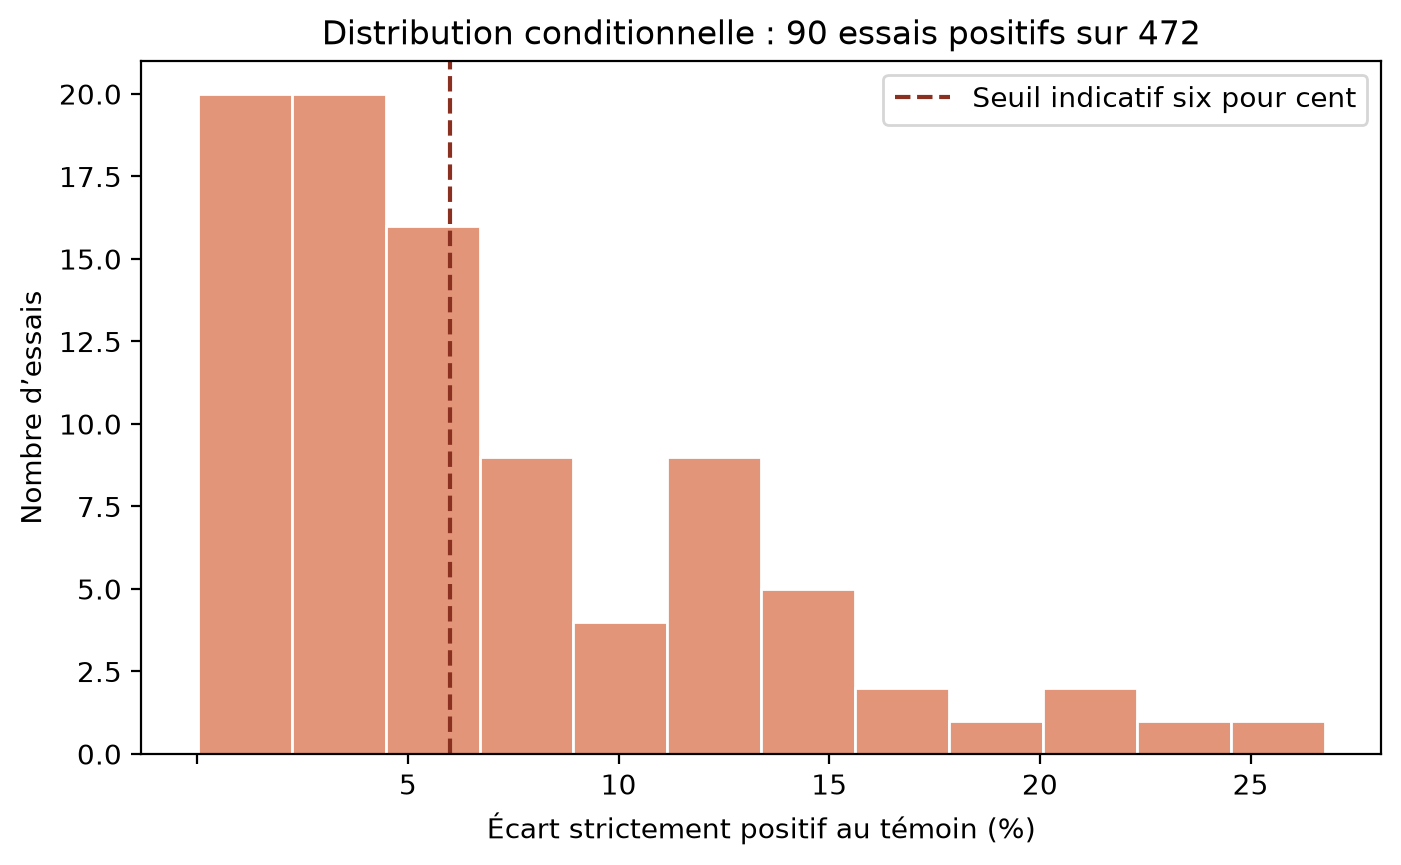

In [13]:
display(Image(filename=str(ROOT/'livraison/duree_figures/presentation_ecarts_positifs.png')))

**Lecture de l'histogramme conditionnel.** Cette distribution porte
seulement sur les écarts strictement positifs des essais de couverture. Le titre
indique leur effectif et l'effectif total ; les autres statuts restent dans la
figure précédente. Les dépassements de six pour cent sont conservés. On ne
présente pas cette distribution filtrée comme celle du catalogue complet.

### 6.4. Covariance, corrélation et moindres carrés

Pour éviter de confondre l’effet du budget et de la taille, cette étude utilise une observation par instance à 1 000 clients, la graine 4101 et dix secondes de recherche : 60 couples. X est la durée de construction et Y la durée finale du profil hybride.

$$\operatorname{Cov}(X,Y)=N^{-1}\sum_i(x_i-\bar x)(y_i-\bar y),\quad r=\frac{\operatorname{Cov}(X,Y)}{\sigma_X\sigma_Y}.$$

La droite $\widehat y=ax+b$ minimise $\sum_i(y_i-ax_i-b)^2$, avec $a=\operatorname{Cov}(X,Y)/v_X$ et $b=\bar y-a\bar x$. La pente mesure l’association observée des durées ; l’interception ne s’interprète pas comme une durée réelle à extrapoler hors des données.

Les calculs donnent **r = 0.9131**, **a = 1.0512**, **b = -13752.4000** et **R² = 0.8338**. Ils décrivent ce lot, sans démontrer un effet causal du moteur ni une garantie prédictive sur une instance nouvelle.

In [14]:
p=pd.read_csv(ROOT/'results/time_objective/catalogue/regression.csv')
x=p.initial_duration.to_numpy();y=p.duration.to_numpy()
cov=np.mean((x-x.mean())*(y-y.mean()))
assert np.isclose(cov,np.cov(x,y,ddof=0)[0,1])
r=cov/(x.std(ddof=0)*y.std(ddof=0))
a=cov/x.var(ddof=0);b=y.mean()-a*x.mean()
a_np,b_np=np.linalg.lstsq(np.c_[x,np.ones(len(x))],y,rcond=None)[0]
assert np.allclose([a,b],[a_np,b_np])
assert np.isclose(r,np.corrcoef(x,y)[0,1])
yp=a*x+b
SCT=((y-y.mean())**2).sum();SCR=((yp-y.mean())**2).sum();SCE=((y-yp)**2).sum()
R2=1-SCE/SCT
assert np.isclose(SCT,SCR+SCE) and np.isclose(R2,r*r)
print('Covariance',cov,'Pearson',r,'a',a,'b',b,'R²',R2)
print('SCT',SCT,'SCR',SCR,'SCE',SCE)

Covariance

 284197949.8013 Pearson 0.9131048308422159 a 1.0512282348000792 b -13752.399983180032 R² 0.8337604321073924
SCT 21499478574.316 SCR 17925414546.205322 SCE 3574064028.110669


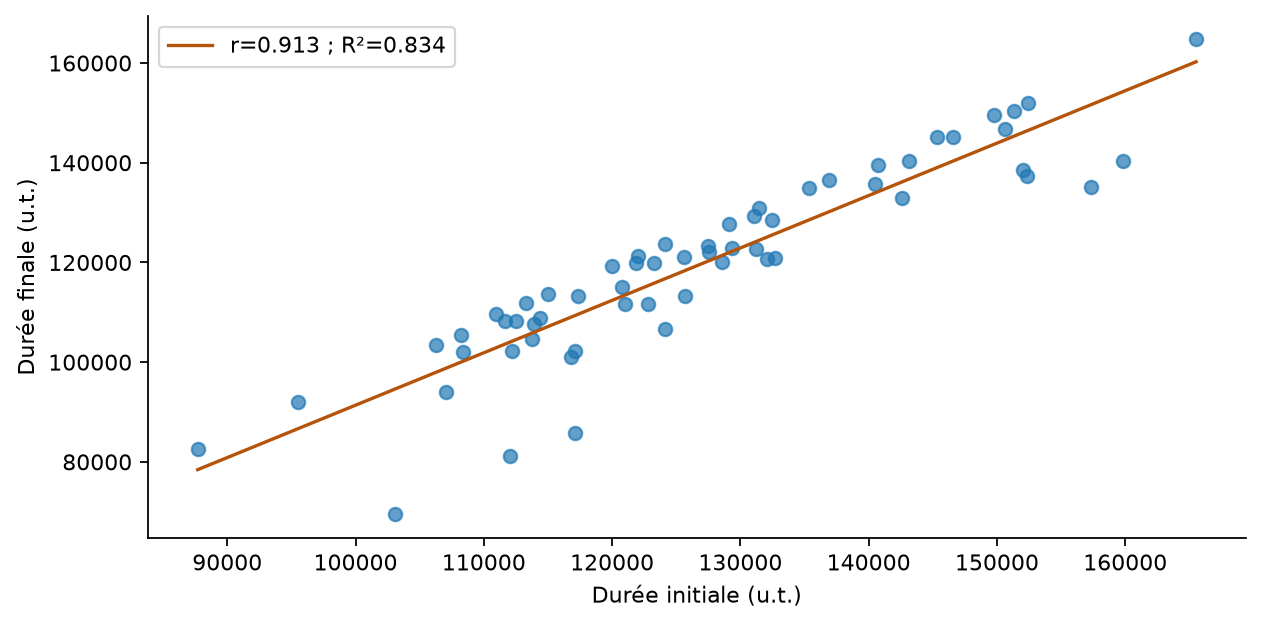

In [15]:
display(Image(filename=str(ROOT/'livraison/duree_figures/regression.png')))

**Lecture du nuage de points.** Un point représente une instance à 1 000 clients, avec la graine 4101 et le même budget de recherche. L'abscisse est la durée des tournées après construction, pas le temps de calcul de cette construction ; l'ordonnée est leur durée après recherche hybride. La droite est ajustée par moindres carrés sur les soixante couples. La corrélation positive montre que les instances ayant de grandes durées initiales tendent également à avoir de grandes durées finales.

**Intérêt et limites.** Cette figure relie la qualité de départ au résultat final, après l'étude de dispersion. Elle ne mesure pas directement un gain, ne prouve pas une causalité et ne signifie pas que le moteur explique 83,4 % d'amélioration. Les services et les caractéristiques des instances contribuent aussi à l'association. La convergence suivante complète cette photographie finale en montrant quand les améliorations apparaissent.

La décomposition SCT = SCR + SCE sépare la variabilité totale, la part associée à la droite ajustée et les résidus. Avec une interception, $R^2=1-\mathrm{SCE}/\mathrm{SCT}=r^2$ en régression linéaire simple. Un R² élevé ne signifie pas que la méthode a causé cette proportion d’amélioration.

### 6.5. Convergence et comparaison des méthodes

Nous alignons les traces sur le temps après construction. Chaque trace est une fonction en escalier du meilleur coût connu ; après l’arrêt d’un essai, sa dernière valeur est conservée jusqu’à l’horizon commun. La fin de la courbe moyenne est vérifiée contre la moyenne des durées finales du même lot. La zone représente ± un écart-type descriptif entre graines, et non un intervalle de confiance.

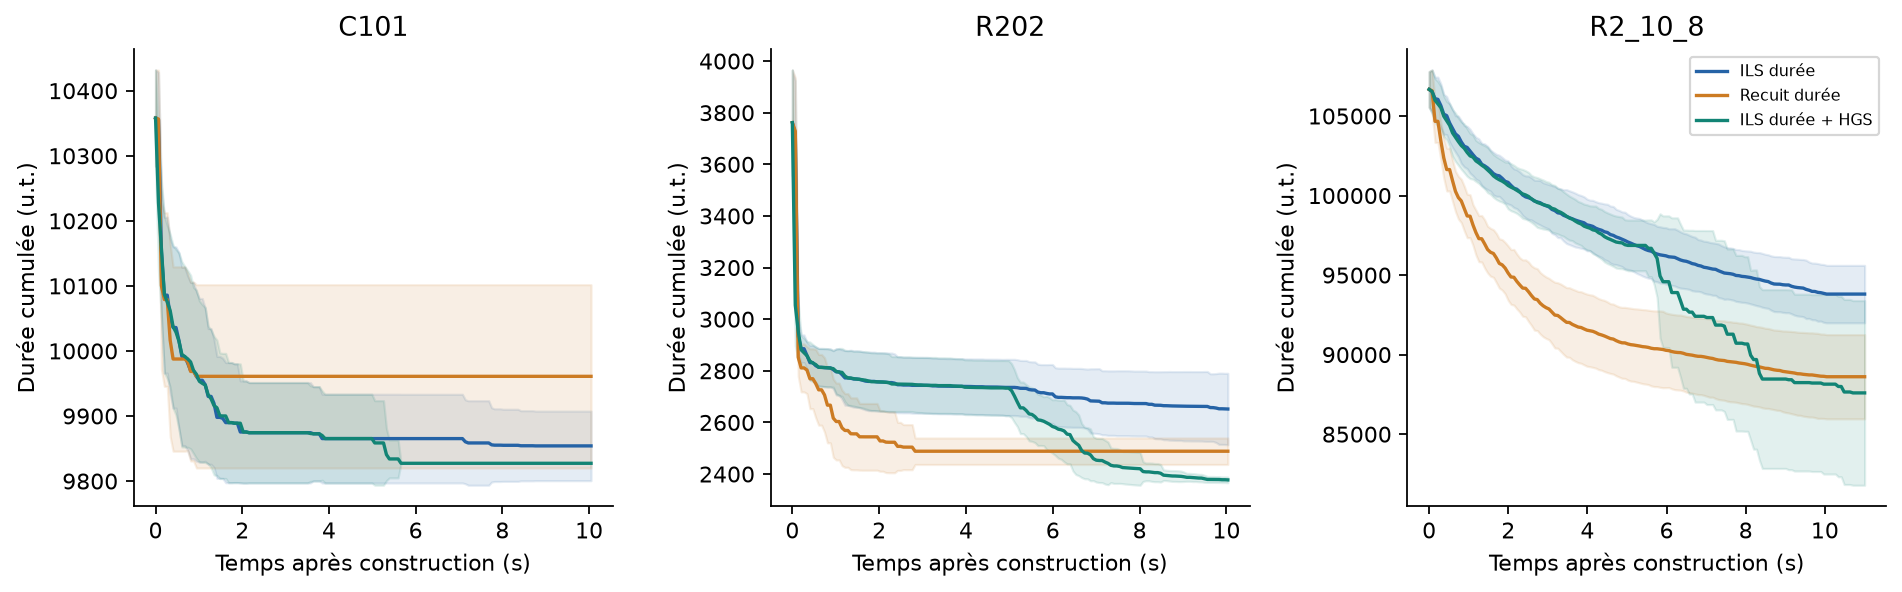

In [16]:
display(Image(filename=str(ROOT/'livraison/duree_figures/convergence.png')))

**Lecture des courbes.** L'axe horizontal mesure les secondes écoulées après la construction ; l'axe vertical mesure la meilleure durée des tournées trouvée jusque-là, moyennée sur vingt graines. Les trois couleurs correspondent à l'ILS, au recuit et au profil hybride. Les bandes représentent plus ou moins un écart-type descriptif entre graines, et non un intervalle de confiance. Une courbe descendante signale de nouvelles améliorations ; un plateau indique qu'aucune amélioration supplémentaire n'est enregistrée dans cette période.

**Interprétation et continuité.** Le profil hybride passe de l'ILS au HGS après environ cinq secondes, hors préparation : sa baisse plus tardive sur R202 et R2_10_8 est cohérente avec cette succession. La courbe ne suffit toutefois pas à isoler causalement l'effet du HGS ; une ablation à budget égal serait nécessaire. Après les distributions des résultats finaux, cette figure montre le compromis entre qualité, temps et variabilité. Le tableau suivant récapitule les valeurs finales et le calcul total, construction comprise.

| instance   | method   |   Essais |   Positifs |   References_depassees |   References_egalees |   Non_comparables | Moyenne_positive_pct   | Mediane_positive_pct   |   Positifs_superieurs_6 |
|:-----------|:---------|---------:|-----------:|-----------------------:|---------------------:|------------------:|:-----------------------|:-----------------------|------------------------:|
| C101       | hybrid   |       20 |          0 |                      0 |                   20 |                 0 | Non applicable         | Non applicable         |                       0 |
| C101       | ils      |       20 |          4 |                      0 |                   16 |                 0 | 1.3605                 | 1.3605                 |                       0 |
| C101       | sa       |       20 |         11 |                      0 |                    9 |                 0 | 2.4730                 | 2.4697                 |                       0 |
| R202       | hybrid   |       20 |          0 |                     20 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
| R202       | ils      |       20 |          0 |                     20 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
| R202       | sa       |       20 |          0 |                     20 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
| R2_10_8    | hybrid   |       20 |          0 |                     20 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
| R2_10_8    | ils      |       20 |          0 |                     20 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |
| R2_10_8    | sa       |       20 |          0 |                     20 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |

Sur ce lot de vingt graines par cas, l’hybride présente la durée moyenne la plus faible pour les trois cas. Les distributions se recouvrent, notamment sur la grande instance : cette observation descriptive ne constitue pas un test de significativité ni une preuve de supériorité sur tout le catalogue.

Ces moyennes et dispersions comparent des méthodes à effort de recherche égal. Nous ne retenons pas seulement le meilleur essai ; un mécanisme plus complexe peut régresser sur un cas. Les trois cas ont été choisis pour leur contraste et ne permettent pas une conclusion universelle de supériorité.

### 6.6. Taille des instances et temps d'exécution réel

Le temps de calcul est une seconde mesure, distincte de la durée des tournées minimisée. Pour toutes les tailles, le budget de recherche est dix secondes ; le calcul total comprend en plus la construction et la préparation. Nous utilisons les temps effectivement enregistrés et donnons le même poids à chaque instance après moyenne de ses graines.

|   Clients |   Instances | Calcul total moyen (s)   |
|----------:|------------:|:-------------------------|
|       100 |          56 | 10,044                   |
|       200 |          60 | 10,143                   |
|       400 |          60 | 10,558                   |
|       600 |          60 | 11,336                   |
|       800 |          60 | 12,611                   |
|      1000 |          60 | 14,279                   |

![Temps de calcul total selon la taille, pour dix secondes de recherche.](../livraison/duree_figures/taille_temps.png)

**Lecture et intérêt.** Les points représentent le calcul total moyen par taille, et la ligne pointillée le budget de recherche commun. Le total passe de 10,04 s à 100 clients à 14,28 s à 1 000 clients. Ce surplus renseigne sur le coût pratique de construction et de préparation ; il montre pourquoi « dix secondes de recherche » ne signifie pas « dix secondes du lancement au résultat ». Après les courbes de qualité pendant la recherche, ce graphique complète le compromis qualité–temps par le coût réellement attendu par l'utilisateur.

**Limite.** Puisque l'arrêt de la recherche dépend d'un budget fixé, ces points ne permettent pas de déduire une complexité asymptotique. Il faudrait aussi chronométrer une quantité de travail identique, comme un nombre de mouvements, pour étudier intrinsèquement le passage à l'échelle.

### 6.7. Vérification exhaustive des écarts et du seuil de 6 %

Nous avons recalculé les horaires et contraintes de chacune des 646 solutions enregistrées et des 356 plans témoins, sur les fichiers originaux vérifiés par empreinte. Les durées sont comparées aux coûts enregistrés et chaque écart est recalculé par $100(T/T_{\mathrm{témoin}}-1)$. Les 646 solutions sont réalisables. Les tableaux exhaustifs `TOUS_LES_ESSAIS_DUREE.csv` et `TOUTES_LES_INSTANCES_DUREE.csv` sont dans `results/time_objective/revision_duree/` ; ils conservent aussi le budget, le temps réel et le chemin du résultat source.

Le seuil est appliqué à l'écart signé : « au plus +6 % » signifie ne pas dépasser la durée du témoin de plus de 6 %. Une valeur négative importante n'est pas un échec de ce critère. Ce critère ne certifie pas une proximité de 6 % avec l'optimum temporel inconnu. Le bilan suivant porte uniquement sur les 472 essais hybrides de couverture ; les répétitions des autres méthodes restent dans le CSV de tous les essais.

| Clients | Instances | Instances > 6 % (moyenne) | Essais hybrides | Essais > 6 % | Pire écart essai / statut |
| --- | --- | --- | --- | --- | --- |
| 100 | 56 | 0 | 112 | 0 | Référence égalée — optimalité non démontrée |
| 200 | 60 | 0 | 60 | 0 | Référence dépassée — solution améliorante validée |
| 400 | 60 | 0 | 60 | 0 | 2.6750 % |
| 600 | 60 | 3 | 60 | 3 | 15.2100 % |
| 800 | 60 | 6 | 60 | 6 | 20.8860 % |
| 1000 | 60 | 14 | 120 | 29 | 26.7670 % |

**Bilan du catalogue mesuré : 23 instances sur 356 dépassent +6 % en moyenne.** Une moyenne globale favorable n'annule pas ces dépassements ; la liste complète figure dans `INSTANCES_AU_DESSUS_DE_6.csv`. Les cas suivants sont ceux à améliorer, sans retirer leurs essais du bilan :

| instance | n | attempts | Moyenne positive conditionnelle — mean_delta_reference_pct / statut | mean_calculation_s |
| --- | --- | --- | --- | --- |
| C1_10_6 | 1000 | 2 | 24.9690 % (positifs 2/2) | 14,510 |
| C1_8_1 | 800 | 1 | 20.8862 % (positifs 1/1) | 12,607 |
| C2_10_7 | 1000 | 2 | 19.8401 % (positifs 2/2) | 14,004 |
| C2_10_2 | 1000 | 2 | 15.7624 % (positifs 2/2) | 14,420 |
| C1_6_1 | 600 | 1 | 15.2101 % (positifs 1/1) | 11,290 |
| C2_10_1 | 1000 | 2 | 14.4487 % (positifs 2/2) | 13,862 |
| C2_8_7 | 800 | 1 | 14.3805 % (positifs 1/1) | 12,732 |
| C2_10_5 | 1000 | 2 | 13.3497 % (positifs 2/2) | 14,517 |
| C2_10_3 | 1000 | 2 | 12.5247 % (positifs 2/2) | 14,805 |
| C2_10_9 | 1000 | 2 | 11.6521 % (positifs 2/2) | 14,059 |
| C1_10_2 | 1000 | 2 | 11.2576 % (positifs 2/2) | 14,773 |
| C2_10_6 | 1000 | 2 | 10.8041 % (positifs 2/2) | 13,954 |
| C1_10_3 | 1000 | 2 | 9.9139 % (positifs 2/2) | 14,273 |
| C1_8_7 | 800 | 1 | 9.5962 % (positifs 1/1) | 12,454 |
| C1_10_5 | 1000 | 2 | 9.3503 % (positifs 2/2) | 14,575 |
| C1_8_6 | 800 | 1 | 8.6544 % (positifs 1/1) | 12,562 |
| C1_10_7 | 1000 | 2 | 7.9884 % (positifs 2/2) | 14,178 |
| C1_8_2 | 800 | 1 | 7.1754 % (positifs 1/1) | 12,449 |
| C1_10_4 | 1000 | 2 | 6.8272 % (positifs 2/2) | 14,013 |
| C1_6_7 | 600 | 1 | 6.7669 % (positifs 1/1) | 11,260 |
| C2_6_2 | 600 | 1 | 6.7347 % (positifs 1/1) | 11,536 |
| C1_8_3 | 800 | 1 | 6.6262 % (positifs 1/1) | 12,532 |
| C2_10_8 | 1000 | 2 | 6.3880 % (positifs 2/2) | 13,935 |

**Optimisations exploratoires, distinctes de la campagne.** Nous avons testé des départs Clarke–Wright et insertion séquentielle, sélectionnés en durée, suivis de la recherche locale externe de PyVRP avec des voisinages de 40, 60, 80 puis 120 clients. Quatre départs sont essayés dans cette variante. Les données et contraintes restent identiques, et chaque solution ci-dessous est revalidée indépendamment.

| Instance | Graine | Écart campagne / statut | Écart essai local / statut | Durée locale | Calcul local (s) | Réalisable |
| --- | --- | --- | --- | --- | --- | --- |
| C1_10_6 | 4101 | 23.1710 % | 6.2840 % | 142159,600 | 5,311 | True |
| C1_10_6 | 4102 | 26.7670 % | 5.8560 % | 141588,000 | 5,194 | True |
| C1_8_1 | 4101 | 20.8860 % | 0.3050 % | 98001,700 | 3,385 | True |
| C2_10_7 | 4101 | 20.8930 % | 6.8780 % | 114295,300 | 6,173 | True |
| C2_10_7 | 4102 | 18.7870 % | 6.9530 % | 114375,200 | 6,165 | True |

Ces paramètres ont été explorés sur des cas déjà identifiés comme difficiles : ce sont des résultats de mise au point, pas une validation indépendante ni une nouvelle moyenne sur 356 instances. Les temps locaux sont mesurés après préchauffage ; ils concernent le calcul de chaque variante, sans absorber le coût des expériences exploratoires antérieures. Sur C1_10_6, les deux écarts sont 6,28 % et 5,86 %, soit 6,07 % en moyenne. Les quatre départs n'ont pas amélioré les résultats du premier essai renforcé sur ce cas ; le temps supplémentaire n'apporte donc pas ici de gain mesurable. Les résultats initiaux et locaux restent dans des colonnes et fichiers distincts.

### 6.8. Relier une solution réelle à sa carte et à ses horaires

Les schémas suivants reprennent deux solutions de la campagne, avec la graine 4101 et la méthode hybride. Ils ne proviennent pas des essais locaux d'optimisation et n'introduisent aucune résolution supplémentaire. C101 illustre un cas groupé stable ; R2_10_8 fournit le contraste avec une grande instance plus variable.


![C101 : carte complète et détail horaire d'une tournée du même essai.](../livraison/duree_figures/C101_carte_horaires.png)

**Lecture de C101.** À gauche, les lignes relient les visites dans leur ordre réel et reviennent au dépôt carré ; cette vue situe toutes les tournées. La tournée en bleu est celle détaillée à droite : la tournée 1, choisie car son attente est maximale dans cet essai (0.0 u.t.). Dans le diagramme horaire, le gris correspond aux trajets, l'orange aux attentes et le vert aux services ; quelques numéros de clients donnent des repères sans superposer tous les identifiants. Tous les segments de cette tournée sont conservés. Les axes spatiaux de la carte et l'axe temporel du diagramme ont donc des significations différentes.

**Intérêt et lien avec les statistiques.** La carte explique l'organisation des trajets ; le diagramme montre pourquoi cette organisation doit aussi être évaluée dans le temps. Ensemble, ils relient la représentation en graphe du début aux durées mesurées dans les tableaux. Cette solution individuelle aide à comprendre le fonctionnement, mais la stabilité et la qualité générale doivent rester évaluées à partir des répétitions et du catalogue complet.


![R2_10_8 : carte complète et détail horaire d'une tournée du même essai.](../livraison/duree_figures/R2_10_8_carte_horaires.png)

**Lecture de R2_10_8.** À gauche, les lignes relient les visites dans leur ordre réel et reviennent au dépôt carré ; cette vue situe toutes les tournées. La tournée en bleu est celle détaillée à droite : la tournée 16, choisie car son attente est maximale dans cet essai (1224.9 u.t.). Dans le diagramme horaire, le gris correspond aux trajets, l'orange aux attentes et le vert aux services ; quelques numéros de clients donnent des repères sans superposer tous les identifiants. Tous les segments de cette tournée sont conservés. Les axes spatiaux de la carte et l'axe temporel du diagramme ont donc des significations différentes.

**Intérêt et lien avec les statistiques.** La carte explique l'organisation des trajets ; le diagramme montre pourquoi cette organisation doit aussi être évaluée dans le temps. Ensemble, ils relient la représentation en graphe du début aux durées mesurées dans les tableaux. Cette solution individuelle aide à comprendre le fonctionnement, mais la stabilité et la qualité générale doivent rester évaluées à partir des répétitions et du catalogue complet.


### 6.9. Optimisation ciblée des dépassements en durée

**Périmètre.** Les 23 instances dépassant +6 % en moyenne et trois autres ayant un essai individuel au-dessus de +6 % ont été sélectionnées après l'audit initial. Les 26 instances représentent 43 couples instance–graine. Cette sélection est une mise au point sur les difficultés observées, pas un nouveau test indépendant sur tout le catalogue.

**Modifications réellement exécutées.** Le prototype `algo/duration_refine.py` compare des constructions Clarke–Wright et insertion séquentielle, puis les améliore avec la recherche locale externe de PyVRP 0.12.2. Les voisinages spatiaux et temporels sont élargis de 40 à 60, 80 et 120 clients. Jusqu'à quatre départs diversifient les constructions. Le réservoir de tournées est maintenant évalué en **durée** : un partitionnement choisit des tournées déjà réalisables en couvrant chaque client exactement une fois, sous la borne de flotte. Le mode historique distance reste explicite et les tests vérifient que deux ordres de même distance sont correctement départagés selon leurs attentes.

**Objectif et validité.** Les départs restent fixés à zéro et le coût reste la somme des trajets, attentes et services. Aucune référence n'est transmise au solveur. Chaque résultat final est contrôlé indépendamment sur les données originales. Une optimalité éventuelle du partitionnement concerne uniquement les tournées disponibles dans le réservoir, pas le CVRPTW complet.

**Budgets.** Le premier prototype demande au plus dix secondes de calcul au total, après préchauffage ; les appels natifs terminent avant d'être contrôlés, donc le temps observé et tout dépassement sont conservés. Les essais encore au-dessus du seuil peuvent être prolongés par le HGS en durée. Dans ce cas, le temps cumulé inclut intégralement la construction et la recherche du premier prototype, plus la continuation et sa préparation. Ces essais plus longs sont identifiés ; ils ne sont pas présentés comme des résultats à dix secondes. La campagne initiale allouait dix secondes à la recherche seule, avec construction ajoutée : les deux conventions restent visibles.

**Résultats par instance.** Les colonnes avant/après utilisent les mêmes graines disponibles. Le pire essai est affiché pour ne pas masquer un dépassement par une moyenne favorable.

| Instance | Clients | Essais | Réalisables | Moyenne positive conditionnelle — Avant moyen / statut | Moyenne positive conditionnelle — Prototype moyen / statut | Moyenne positive conditionnelle — Après moyen / statut | Pire après / statut | Calcul cumulé moyen (s) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| C1_10_2 | 1000 | 2 | 2 | 11.2576 % (positifs 2/2) | 3.8889 % (positifs 2/2) | 3.5435 % (positifs 2/2) | 4.0020 % | 15,203 |
| C1_10_3 | 1000 | 2 | 2 | 9.9139 % (positifs 2/2) | 2.0192 % (positifs 2/2) | 2.0192 % (positifs 2/2) | 2.2920 % | 4,744 |
| C1_10_4 | 1000 | 2 | 2 | 6.8272 % (positifs 2/2) | Aucun écart positif (effectif 2) | Aucun écart positif (effectif 2) | Référence dépassée — solution améliorante validée | 4,419 |
| C1_10_5 | 1000 | 2 | 2 | 9.3503 % (positifs 2/2) | 1.7167 % (positifs 2/2) | 1.7167 % (positifs 2/2) | 2.6090 % | 4,596 |
| C1_10_6 | 1000 | 2 | 2 | 24.9690 % (positifs 2/2) | 5.3361 % (positifs 2/2) | 2.8668 % (positifs 2/2) | 3.8820 % | 25,113 |
| C1_10_7 | 1000 | 2 | 2 | 7.9884 % (positifs 2/2) | 2.7241 % (positifs 2/2) | 2.7241 % (positifs 2/2) | 2.9130 % | 4,796 |
| C1_10_8 | 1000 | 2 | 2 | 5.9105 % (positifs 2/2) | 2.6646 % (positifs 2/2) | 2.6646 % (positifs 2/2) | 3.0580 % | 4,583 |
| C1_10_9 | 1000 | 2 | 2 | 5.6003 % (positifs 2/2) | 2.7778 % (positifs 2/2) | 2.7778 % (positifs 2/2) | 2.8850 % | 4,564 |
| C1_6_1 | 600 | 1 | 1 | 15.2101 % (positifs 1/1) | Aucun écart positif (effectif 1) | Aucun écart positif (effectif 1) | Référence dépassée — solution améliorante validée | 2,030 |
| C1_6_7 | 600 | 1 | 1 | 6.7669 % (positifs 1/1) | 1.1387 % (positifs 1/1) | 1.1387 % (positifs 1/1) | 1.1390 % | 1,956 |
| C1_8_1 | 800 | 1 | 1 | 20.8862 % (positifs 1/1) | 0.1618 % (positifs 1/1) | 0.1618 % (positifs 1/1) | 0.1620 % | 2,991 |
| C1_8_2 | 800 | 1 | 1 | 7.1754 % (positifs 1/1) | 4.9611 % (positifs 1/1) | 3.0141 % (positifs 1/1) | 3.0140 % | 23,419 |
| C1_8_3 | 800 | 1 | 1 | 6.6262 % (positifs 1/1) | 3.1898 % (positifs 1/1) | 3.1898 % (positifs 1/1) | 3.1900 % | 3,167 |
| C1_8_6 | 800 | 1 | 1 | 8.6544 % (positifs 1/1) | 5.6124 % (positifs 1/1) | 1.2350 % (positifs 1/1) | 1.2350 % | 23,683 |
| C1_8_7 | 800 | 1 | 1 | 9.5962 % (positifs 1/1) | 1.5247 % (positifs 1/1) | 1.5247 % (positifs 1/1) | 1.5250 % | 3,262 |
| C2_10_1 | 1000 | 2 | 2 | 14.4487 % (positifs 2/2) | 1.4064 % (positifs 2/2) | 1.4064 % (positifs 2/2) | 1.8860 % | 5,932 |
| C2_10_2 | 1000 | 2 | 2 | 15.7624 % (positifs 2/2) | 5.0252 % (positifs 2/2) | 3.0796 % (positifs 2/2) | 3.1090 % | 42,467 |
| C2_10_3 | 1000 | 2 | 2 | 12.5247 % (positifs 2/2) | 3.9879 % (positifs 2/2) | 2.0003 % (positifs 2/2) | 3.1550 % | 16,741 |
| C2_10_4 | 1000 | 2 | 2 | 5.7202 % (positifs 2/2) | Aucun écart positif (effectif 2) | Aucun écart positif (effectif 2) | Référence dépassée — solution améliorante validée | 5,541 |
| C2_10_5 | 1000 | 2 | 2 | 13.3497 % (positifs 2/2) | 1.9144 % (positifs 2/2) | 1.9144 % (positifs 2/2) | 2.0990 % | 5,824 |
| C2_10_6 | 1000 | 2 | 2 | 10.8041 % (positifs 2/2) | 2.1646 % (positifs 2/2) | 2.1646 % (positifs 2/2) | 2.2890 % | 5,902 |
| C2_10_7 | 1000 | 2 | 2 | 19.8401 % (positifs 2/2) | 7.2446 % (positifs 2/2) | 4.9785 % (positifs 2/2) | 5.1920 % | 56,216 |
| C2_10_8 | 1000 | 2 | 2 | 6.3880 % (positifs 2/2) | 2.1486 % (positifs 2/2) | 2.1486 % (positifs 2/2) | 2.5270 % | 5,457 |
| C2_10_9 | 1000 | 2 | 2 | 11.6521 % (positifs 2/2) | 4.1736 % (positifs 2/2) | 4.1736 % (positifs 2/2) | 4.5470 % | 16,070 |
| C2_6_2 | 600 | 1 | 1 | 6.7347 % (positifs 1/1) | 4.1912 % (positifs 1/1) | Aucun écart positif (effectif 1) | Référence dépassée — solution améliorante validée | 22,782 |
| C2_8_7 | 800 | 1 | 1 | 14.3805 % (positifs 1/1) | 4.8700 % (positifs 1/1) | 3.5062 % (positifs 1/1) | 3.5060 % | 24,522 |

Sur ce lot ciblé, **43/43 essais sont réalisables et au plus à +6 %**, 0 essais restent au-dessus et 0 essais sont en échec. Les moyennes positives sont conditionnelles et leur effectif est indiqué pour chaque instance ; les valeurs individuelles et les chemins des solutions sont conservés dans `results/time_objective/outliers10/AVANT_APRES_ESSAIS.csv`.

**Portée.** Les valeurs précédentes des 646 résolutions ne sont pas remplacées. Ce tableau documente une nouvelle variante sur les cas ciblés et ne constitue ni une nouvelle moyenne indépendante des 356 instances, ni une preuve de gap à un optimum temporel. Le seuil porte toujours sur la durée du plan témoin réévalué. Les valeurs négatives, les temps supplémentaires et les dépassements éventuels sont conservés.

![Évolution des écarts moyens des 26 instances ciblées, sur les mêmes graines.](../livraison/duree_figures/presentation_optimisation_statuts.png)

**Lecture du graphique.** Les deux barres classent les mêmes 43 couples avant et après la reprise, en références dépassées, égalées et écarts positifs. Le tableau des statistiques conditionnelles précise les effectifs ; les coûts et temps originaux sont conservés.

**Intérêt et continuité.** Après l'audit des dépassements, ce graphique rend visible le progrès et permet de repérer les cas restant proches du seuil. Il complète le tableau sans remplacer la colonne du pire essai : un point moyen sous la ligne ne suffirait pas à valider toutes les graines. Il concerne les 26 instances sélectionnées, et non l'ensemble du catalogue ni un optimum temporel connu.

**Vérification du code.** La suite complète exécutée après ajout du prototype compte 168 tests réussis, 0 échecs et 0 tests ignorés. Le détail est conservé dans `results/time_objective/outliers10/tests.xml`. Les tests comprennent notamment la sélection en durée lorsque les distances sont identiques, la faisabilité du prototype et les contrôles historiques de non-régression.

**Diagnostic du partitionnement.** Sur 43 appels au réservoir, 21 améliorent directement la durée de l'archive avant la dernière recherche locale. Le plus grand gain de cette étape vaut 1888.8 unités de durée. Ce diagnostic compare l'entrée et la sortie de l'étape dans les traces ; il ne remplace pas une étude d'ablation complète à budget identique.

#### Pourquoi les durées diminuent et ce que nous conservons

Les constructions alternatives offrent plusieurs répartitions des clients au lieu de dépendre des seules insertions regret-2. La recherche locale externe réévalue les enchaînements temporels et explore un voisinage progressivement plus large. Le partitionnement peut ensuite choisir une combinaison de tournées que la sélection d'une solution complète unique ne proposerait pas. Ces changements restent guidés par la durée totale : moins de véhicules n'est pas un objectif prioritaire ; un regroupement n'est retenu que s'il améliore la durée et respecte les contraintes.

Le gain final est vérifiable physiquement : les temps de service restent inchangés, et la différence de durée provient exclusivement des trajets et des attentes. Le tableau suivant décompose trois cas contrastés, en moyenne sur leurs graines disponibles. Il distingue ce que les résultats démontrent de l'attribution à un opérateur : sans ablation complète, nous ne pouvons pas donner une part causale précise de l'amélioration à chaque changement.

| Instance   | Trajets avant   | Trajets après   | Attentes avant   | Attentes après   | Services inchangés   |
|:-----------|:----------------|:----------------|:-----------------|:-----------------|:---------------------|
| C1_10_6    | 70491,950       | 46912,100       | 6660,000         | 677,100          | 90000,000            |
| C1_8_6     | 33106,500       | 26377,600       | 824,400          | 319,800          | 72000,000            |
| C2_10_7    | 37587,700       | 22080,750       | 569,300          | 183,300          | 90000,000            |

**Recherche supplémentaire sous le seuil de 6 %.** Une deuxième prolongation a ciblé 13 essais encore au-dessus de +4 %. Chacun reçoit vingt secondes de HGS, avec 120 voisins et un autre décalage de graine. 10 essais améliorent leur parent, 3 restent sans gain et 0 échouent. Le tableau `CONTINUATIONS_ET_GAINS.csv` conserve chaque résultat. Plusieurs paramètres changent ensemble : ce lot mesure l'effet de cette continuation, sans isoler l'effet du voisinage de celui du budget ou de la graine.

**Conservation des meilleurs résultats.** Les tournées retenues sont enregistrées dans `results/time_objective/best_duration/runs/`, avec leur source et la liste des tentatives. Une candidate ne remplace l'archive que si elle améliore strictement la durée ; une tentative sans progrès laisse donc la meilleure tournée intacte. Son temps de calcul reste cependant ajouté au cumul. Les tableaux `INDEX_MEILLEURS_ESSAIS.csv` et `INDEX_MEILLEURES_INSTANCES.csv` décrivent les 43 essais ciblés et leurs 26 instances.

**Couverture complète.** Les index `COUVERTURE_472_ESSAIS.csv` et `COUVERTURE_356_INSTANCES.csv` reprennent aussi les résultats initiaux des cas non retestés. Ils constituent une archive des meilleures solutions observées, avec des budgets différents et toutes les sources identifiées. Ils ne remplacent pas la campagne initiale à budget fixé. Pour un cas ciblé, le temps total d'archive comprend l'essai initial et toutes les recherches supplémentaires, y compris celles sans gain. Les comparateurs ILS et recuit restent leurs mesures historiques ; ils ne sont pas remplacés par les solutions du profil renforcé.

### 6.10. Sensibilité contrôlée : un facteur à la fois

**Question.** Une amélioration obtenue en changeant ensemble le budget, le voisinage et la graine ne permet pas d'isoler le rôle d'un réglage. Nous ajoutons une étude OFAT (*one factor at a time*) sur un profil hybride précisément défini : notre construction regret-2 et notre ILS, suivis du HGS externe PyVRP. Le partitionnement et le constructeur renforcé ne participent pas à cette expérience ; nous ne lui attribuons donc pas les performances du profil `duration_refined`.

**Plan fixé avant exécution.** Six instances sont retenues : C103, R203 et RC103 à 100 clients ; C2_10_10, R1_10_5 et RC2_10_5 à 1 000 clients. Trois nouvelles graines, 8301–8303, donnent dix-huit couples instance–graine. La configuration témoin est une tolérance ILS de 0,5 % et 40 voisins HGS. Nous changeons uniquement la tolérance vers 0 % ou 2 %, ou uniquement le voisinage vers 80 ou 120. Ces cinq configurations produisent 90 profils évalués ; le témoin commun n'est pas compté deux fois.

**Contrôle des départs et des temps.** Chaque profil dispose de deux secondes d'ILS puis deux secondes de HGS, avec les mêmes données, la même graine appariée et un unique cœur CPU. La construction commune est réellement exécutée une fois par couple instance–graine. Les voisins HGS sont comparés à partir du même préfixe ILS enregistré, vérifié par empreinte ; modifier le voisinage ne modifie donc pas son entrée. Quand la tolérance change, le préfixe ILS est recalculé. Les phases communes sont mutualisées, et leur temps mesuré est facturé dans chaque profil. Le total publié est la **somme recomposée de phases réellement chronométrées**, construction et préparation comprises, pas le chronométrage continu de 90 pipelines indépendants. Le temps physique de chaque tâche et les réutilisations sont aussi enregistrés. L'ordre des tâches est mélangé et fixé dans le protocole.

Le réglage de voisins concerne uniquement le HGS externe ; le voisinage de notre ILS reste fixe. PyVRP borne le nombre effectif à $\min(k,n-1)$ : le réglage nominal 120 correspond donc à 99 voisins pour les cas à 100 clients, et à 120 pour les cas à 1 000 clients. Cette valeur effective est conservée dans le tableau individuel.

**Indicateur apparié.** Pour chaque couple, $D=100(T_{\mathrm{réglage}}/T_{\mathrm{témoin\ de\ réglage}}-1)$. Ici le témoin est la configuration algorithmique à 0,5 % / 40 voisins, pas le plan BKS. Un D négatif indique une amélioration. Nous moyennons d'abord les graines de chaque instance, puis les six instances à poids égal. Les écarts aux plans de référence restent dans le fichier individuel sous leur qualification habituelle, distincte d'un gap à l'optimum temporel.

| Réglage       |   Paires |   Instances | Variation durée finale (%)   | Variation ILS seul (%)   |   Meilleurs |   Égaux |   Moins bons | Total recomposé (s)   |
|:--------------|---------:|------------:|:-----------------------------|:-------------------------|------------:|--------:|-------------:|:----------------------|
| baseline      |       18 |           6 | 0,000                        | 0,000                    |           0 |      18 |            0 | 5,930                 |
| neighbors_120 |       18 |           6 | -0,013                       | 0,000                    |           5 |       9 |            4 | 6,040                 |
| neighbors_80  |       18 |           6 | -0,143                       | 0,000                    |           4 |       9 |            5 | 6,071                 |
| tolerance_0   |       18 |           6 | -0,286                       | 0,496                    |          11 |       4 |            3 | 5,934                 |
| tolerance_002 |       18 |           6 | 0,186                        | 0,445                    |           4 |       5 |            9 | 5,920                 |

![Sensibilité de la durée finale à un réglage modifié isolément.](../livraison/duree_figures/sensibilite_controlee.png)

**Lecture des boîtes.** Chaque boîte rassemble les variations appariées des dix-huit couples instance–graine. Le panneau gauche change la tolérance de notre ILS ; le panneau droit change le voisinage du moteur externe. La ligne zéro représente la configuration témoin, identique à elle-même. Sous zéro, le réglage améliore la durée finale ; au-dessus, il la dégrade. La médiane et la dispersion complètent la moyenne du tableau. Les points extrêmes sont conservés.

**Intérêt et continuité.** Après les optimisations combinées de la section 6.9, cette figure examine un réglage à la fois. Les améliorations et régressions sont comparées au même départ, et les résultats propres à l'ILS sont distingués du résultat après HGS. La dispersion inclut des graines et des instances différentes ; elle n'est pas un intervalle de confiance. Trois graines et six cas ne suffisent pas à établir un meilleur réglage universel. L'effet du budget n'est pas étudié, puisqu'il reste fixe ; nous n'attribuons pas ces résultats aux recherches plus longues de l'archive.


**Faisabilité et portée.** 90/90 profils sont réalisables, avec 0 échecs conservés. Cette campagne est exploratoire, séparée des 646 résolutions initiales et de l’archive des meilleures solutions. Un mauvais résultat au budget court reste publié et n’est pas remplacé par une reprise longue.

**Interprétation mesurée.** Le réglage `tolerance_0` donne une variation moyenne de -0.286 %, avec 11 améliorations, 4 égalités et 3 régressions sur 18 paires. Le réglage `neighbors_80` donne une variation moyenne de -0.143 %, avec 4 améliorations, 9 égalités et 5 régressions sur 18 paires. Le réglage `neighbors_120` donne une variation moyenne de -0.013 %, avec 5 améliorations, 9 égalités et 4 régressions sur 18 paires. Le réglage `tolerance_002` donne une variation moyenne de +0.186 %, avec 4 améliorations, 5 égalités et 9 régressions sur 18 paires. Ces différences ne justifient pas un changement automatique du profil par défaut : une confirmation sur un lot distinct serait nécessaire.

**Attribution du gain.** Avec une tolérance nulle, le coût moyen du préfixe ILS varie ici de +0.496 % : il est donc moins bon que celui du témoin avant l'appel externe. Le résultat final après HGS varie de -0.286 %. Cette différence montre une interaction entre le départ produit et la recherche externe ; elle ne démontre pas que notre ILS autonome est meilleur. Les voisins 80/120 ne changent pas ce préfixe, ce que confirment leurs empreintes identiques. Leurs différences finales concernent bien le réglage du HGS sur ces entrées.

### 6.11. Scénarios géographiques, fenêtres et capacités

**Population comparable.** Cette analyse utilise la campagne initiale à dix secondes de recherche : 356 instances, une observation par instance après moyenne de ses graines. Elle ne mélange pas ces mesures avec l'archive à budgets différents. C désigne les clients groupés, R les clients répartis aléatoirement et RC une organisation mixte. Les six familles C1/C2/R1/R2/RC1/RC2 combinent ces structures et des paramètres temporels et de capacité différents. Nous mesurons les caractéristiques des fichiers originaux, plutôt que supposer que l'indice 2 élargit uniformément toutes les contraintes. Les données ne sont pas modifiées pour construire ces scénarios.

**Indicateurs de difficulté.** Une durée brute plus élevée n'implique pas une mauvaise solution : les nombres de clients et les services diffèrent. Nous examinons aussi le gain par rapport à la construction de la même instance, la part d'attente et le calcul réel. L'écart au témoin reste descriptif : des différences entre familles peuvent venir de la pertinence temporelle variable de leurs références distance, et non seulement de la difficulté intrinsèque.

Le gain depuis la construction est $G=100(T_{\mathrm{construction}}-T_{\mathrm{finale}})/T_{\mathrm{construction}}$. Par exemple, un gain de 19,32 % signifie une diminution de durée de 19,32 % depuis le départ construit ; ce n'est pas un gap de 19,32 % par rapport au BKS. Pour cet indicateur, une valeur positive élevée est une amélioration. La colonne « Écart témoin » utilise une autre référence et doit être interprétée séparément.

| Géographie | Instances | Écart témoin / statut | Gain construction (%) | Part attente (%) | Attente témoin (%) | Calcul moyen (s) |
| --- | --- | --- | --- | --- | --- | --- |
| C | 117 | Voir les effectifs par statut, pas une moyenne globale | 6,633 | 0,371 | 2,501 | 11,507 |
| R | 123 | Voir les effectifs par statut, pas une moyenne globale | 14,610 | 12,221 | 56,824 | 11,511 |
| RC | 116 | Voir les effectifs par statut, pas une moyenne globale | 19,318 | 11,424 | 54,690 | 11,517 |

![Performances par géographie et par taille dans la campagne initiale.](../livraison/duree_figures/presentation_statuts_geographie.png)

**Lecture des statuts géographiques.** Les barres comptent les essais de couverture par géographie et par statut. Les caractéristiques de fenêtres et capacité qui suivent restent calculées par instance ; les granularités ne sont pas confondues.

**Intérêt et continuité.** Le tableau global résume les trois géographies ; les cartes séparent ensuite les tailles pour éviter de confondre structure spatiale et nombre de clients. Elles montrent les cas où la recherche améliore beaucoup son départ, ainsi que ceux où le témoin reste meilleur. Cette lecture conduit à examiner les fenêtres et la capacité, qui participent aussi à la faisabilité des mouvements.

**Fenêtres et capacité : définitions mesurées.** La largeur d'une fenêtre est $l_i-e_i$ ; sa moyenne divisée par H donne une ouverture relative à l'horizon. Ce ratio ne mesure ni la position des fenêtres, ni leur compatibilité avec les trajets. Le ratio moyen $q_i/Q$ mesure la part de camion occupée par un client. La borne $\lceil\sum_i q_i/Q\rceil$ donne un minimum de véhicules lié uniquement aux quantités ; les fenêtres peuvent imposer davantage de tournées. Enfin, le remplissage observé est $\sum_i q_i/(mQ)$ pour m véhicules utilisés, puis moyenné sur les graines.

| Famille   |   Instances | Q min    | Q max    | H min    | H max    | Largeur fenêtre moyenne (u.t.)   | Fenêtre/H (%)   | Demande/Q (%)   | Remplissage (%)   |
|:----------|------------:|:---------|:---------|:---------|:---------|:---------------------------------|:----------------|:----------------|:------------------|
| C1        |          59 | 200,000  | 200,000  | 1236,000 | 1824,000 | 365,145                          | 24,228          | 9,000           | 85,921            |
| C2        |          58 | 700,000  | 700,000  | 3390,000 | 3914,000 | 949,779                          | 25,605          | 2,700           | 81,507            |
| R1        |          62 | 200,000  | 200,000  | 230,000  | 1925,000 | 311,556                          | 31,229          | 8,600           | 83,119            |
| R2        |          61 | 1000,000 | 1000,000 | 1000,000 | 7697,000 | 1424,473                         | 35,564          | 1,724           | 79,900            |
| RC1       |          58 | 200,000  | 200,000  | 240,000  | 1821,000 | 208,800                          | 22,200          | 8,908           | 85,679            |
| RC2       |          58 | 1000,000 | 1000,000 | 960,000  | 7284,000 | 891,451                          | 23,700          | 1,782           | 72,551            |

![Fenêtres, attentes et remplissage : observations à 1 000 clients.](../livraison/duree_figures/contraintes_observees.png)

**Lecture des nuages.** Chaque point est une des soixante instances à 1 000 clients, après moyenne de ses graines. À gauche, nous rapprochons l'ouverture relative moyenne des fenêtres de la part d'attente finale. À droite, nous rapprochons la demande relative à la capacité du remplissage effectif. Les couleurs distinguent C, R et RC. La taille et le budget de recherche sont fixes, mais les autres caractéristiques restent différentes.

**Intérêt et limites.** Ces nuages relient les contraintes du modèle au comportement observé. Une capacité élevée autorise certains regroupements sans les garantir ; les horaires peuvent empêcher de remplir un camion. Des fenêtres longues peuvent aussi laisser subsister des attentes selon leur position et l'ordre des visites. Il s'agit d'associations descriptives, pas d'une expérience modifiant une seule contrainte : géographie, services, horizon et demandes peuvent se confondre. Nous ne concluons donc pas à un effet causal isolé de Q ou de la largeur des fenêtres. Les limites de l'approche et les réglages contrôlés de la section précédente complètent cette lecture.


**Lecture du bilan.** Les gains depuis la construction et les parts d’attente restent des indicateurs de durée, distincts des gaps de benchmark. Les comparaisons au témoin sont décrites par les effectifs de chaque statut ci-dessous ; une moyenne signée de toute une géographie n’est pas requalifiée en moyenne positive.

| geo   |   Essais |   Positifs |   References_depassees |   References_egalees |   Non_comparables | Moyenne_positive_pct   | Mediane_positive_pct   |   Positifs_superieurs_6 |
|:------|---------:|-----------:|-----------------------:|---------------------:|------------------:|:-----------------------|:-----------------------|------------------------:|
| C     |      154 |         87 |                     43 |                   24 |                 0 | 6.9063                 | 4.8712                 |                      38 |
| R     |      166 |          3 |                    163 |                    0 |                 0 | 1.2366                 | 1.4576                 |                       0 |
| RC    |      152 |          0 |                    152 |                    0 |                 0 | Non applicable         | Non applicable         |                       0 |

**Association et causalité.** Sur les soixante cas à 1 000 clients, la corrélation de Pearson entre ouverture relative des fenêtres et part d'attente vaut -0.269, et celle entre demande relative à Q et remplissage vaut 0.227. Ces associations modestes ne suffisent pas à isoler un effet causal des contraintes. La colonne d'attente du témoin rappelle aussi que les plans de référence n'ont pas été sélectionnés pour minimiser ce temps : leurs écarts de durée peuvent différer fortement selon les familles.

### 6.12. Réduction du temps CPU et étude du parallélisme

**Trois temps à distinguer.** La durée des tournées est notre objectif métier, exprimé en unités du benchmark. Le temps écoulé du programme mesure l'attente de l'utilisateur en secondes. Le temps CPU mesure le travail utilisateur et noyau des processeurs. Le parallélisme peut réduire l'attente tout en consommant davantage de CPU : quatre processus occupés chacun dix secondes peuvent représenter environ quarante secondes CPU. Réduire le temps de calcul est un critère de performance, sans remplacer l'objectif de durée ni les contraintes de validité.

**Profilage et modification retenue.** Dans le profil renforcé, la proximité des clients était triée à nouveau à chaque demande de voisins, alors que les données d'une instance restent identiques. Sur le cas instrumenté C1_10_6, les tris NumPy passent de 22 à 1 après ajout du cache. `DurationLocalSearch.neighbors` conserve un ordre stable couvrant les voisinages prévus et réutilise ses préfixes pour 40, 60, 80 et 120 voisins. Une demande plus grande reconstruit cet ordre ; une autre instance reçoit un nouveau cache. Le transfert des voisins vers le moteur est également évité lorsque leur nombre effectif ne change pas. Les tests comparent les listes à celles de PyVRP, y compris après agrandissement et aux bornes de taille.

Cette optimisation est développée dans notre orchestration Python ; la recherche locale reste fournie par PyVRP. Nous ne supprimons pas les vérifications pour gagner du temps. Les données, les opérateurs, les graines et l'objectif restent identiques.

**Comparaison à travail fixé.** C103, C1_10_6, R1_10_5 et RC2_10_5 sont testées avec les graines 8301–8303. Chaque version effectue les mêmes quatre départs et le même programme de recherche : 24 résolutions, soit douze paires. L'ordre avant/après alterne ; le préchauffage est exclu. Le plafond de sécurité de soixante secondes n'est jamais atteint. Les coûts et le nombre d'étapes sont identiques dans les douze paires, et toutes les solutions sont réalisables. Le profilage instrumenté sert à localiser les coûts ; les temps comparatifs ci-dessous sont mesurés sans ce profilage.

Le CPU est mesuré par `time.process_time`, qui inclut les threads natifs du processus, et le temps écoulé par `time.perf_counter`. Le tableau donne les moyennes des trois graines par instance. Le gain CPU vaut $100(1-\overline{C}_{\mathrm{après}}/\overline{C}_{\mathrm{avant}})$ ; il ne s'agit pas d'un gap de tournée au BKS.

| Instance   |   Clients | CPU avant (s)   | CPU après (s)   | Réduction CPU (%)   | Écoulé avant (s)   | Écoulé après (s)   |
|:-----------|----------:|:----------------|:----------------|:--------------------|:-------------------|:-------------------|
| C103       |       100 | 0,167           | 0,146           | 12,500              | 0,166              | 0,167              |
| C1_10_6    |      1000 | 5,036           | 2,995           | 40,538              | 5,280              | 3,177              |
| R1_10_5    |      1000 | 4,479           | 2,417           | 46,047              | 4,771              | 2,615              |
| RC2_10_5   |      1000 | 5,891           | 3,854           | 34,571              | 6,231              | 4,123              |

Sur les douze paires, la somme des temps CPU diminue de **39.57 %**, à coût de tournée identique. Cette valeur concerne le profil renforcé et ce lot ; elle ne s’applique pas rétroactivement à toutes les campagnes ou au moteur ILS autonome.

![CPU et temps écoulé avant/après réutilisation des voisinages.](../livraison/duree_figures/cpu_cache.png)

**Lecture du graphique.** Chaque paire de barres compare les mêmes trois graines, avec le même travail et les mêmes coûts finaux. À gauche, la hauteur est le CPU consommé ; à droite, le temps attendu par l'utilisateur. La baisse montre l'effet du cache, sans retirer de clients, de mouvements ou de contrôles. Les petites durées restent sensibles à la granularité des compteurs Windows et au bruit de la machine.

**Intérêt et continuité.** Après l'analyse des paramètres de recherche, cette figure étudie une accélération de l'implémentation conservant le calcul. Le cache réduit le travail répété ; le parallélisme étudié ensuite répartit ce travail sur plusieurs cœurs et répond à une autre question.

**Parallélisme testé.** Un portefeuille de quatre départs indépendants, graines 9301–9304, résout chaque instance C1_10_6, R1_10_5 et RC2_10_5. Les mêmes tâches, avec quatre départs internes chacune, sont exécutées sur un, deux puis quatre processus, avec deux répétitions et des affinités CPU enregistrées. Cela représente dix-huit portefeuilles et 72 recherches individuelles. Le meilleur résultat du portefeuille est conservé et validé ; les coûts par graine sont identiques entre les niveaux de parallélisme dans ce lot. Cette comparaison garde le travail constant : elle ne donne pas quatre fois plus de départs au mode parallèle.

Le CPU total additionne le parent et tous ses workers. Sous Windows, des handles conservés permettent de lire `GetProcessTimes` après l'arrêt des workers : le tableau des lots inclut donc aussi leurs imports, préchauffages et fermetures. Mesurer uniquement le CPU du parent aurait sous-estimé la consommation. Les tableaux par instance ci-dessous utilisent un pool déjà initialisé ; le premier chargement de l'instance et sa validation restent inclus. Les valeurs moyennes portent sur trois instances et deux répétitions, soit six portefeuilles par réglage.

|   Processus |   Portefeuilles | Écoulé moyen (s)   | CPU cumulé moyen (s)   | Accélération écoulée   | Variation CPU (%)   |
|------------:|----------------:|:-------------------|:-----------------------|:-----------------------|:--------------------|
|           1 |               6 | 12,820             | 12,122                 | 1,000                  | 0,000               |
|           2 |               6 | 6,834              | 12,935                 | 1,876                  | 6,702               |
|           4 |               6 | 3,919              | 14,089                 | 3,271                  | 16,219              |

![Parallélisme : attendre moins longtemps peut consommer davantage de CPU.](../livraison/duree_figures/cpu_parallelisme.png)

**Lecture des deux panneaux.** Le panneau gauche mesure le délai pour terminer les mêmes quatre recherches et valider leur meilleure solution. Le panneau droit additionne le travail CPU des processus pendant ce portefeuille. Les unités sont des secondes dans les deux cas, mais leur sens diffère : les valeurs du panneau droit ne doivent pas être divisées par le nombre de processus. Tous les résultats de durée restent identiques à travail égal dans cette expérience.

**Intérêt et choix.** Le cache réduit le CPU de chaque recherche ; multiplier les processus réduit surtout la latence. Dans le lot mesuré, le mode séquentiel optimisé reste le choix économe en CPU, tandis que plusieurs processus conviennent si le délai de réponse est prioritaire. L'autorisation du multithreading ne signifie donc pas qu'utiliser tous les cœurs minimise la consommation CPU. Notre expérimentation emploie plusieurs processus pour isoler les états et les graines sous CPython 3.12 ; ce n'est pas l'activation automatique de threads dans PyVRP.

**Démarrage et fermeture inclus.** Chaque lot suivant exécute les trois instances avec le même portefeuille. Le temps total part de la création du pool et se termine après son arrêt ; il exclut seulement le lancement initial de l'interpréteur parent, commun au protocole. Les temps CPU des workers couvrent leur vie entière. Le coût du démarrage peut réduire l'intérêt du parallélisme pour une seule petite instance.

|   Processus |   Lots | Démarrage moyen (s)   | Lot complet écoulé (s)   | Lot complet CPU (s)   |
|------------:|-------:|:----------------------|:-------------------------|:----------------------|
|           1 |      2 | 1,684                 | 40,542                   | 38,016                |
|           2 |      2 | 1,787                 | 22,728                   | 42,008                |
|           4 |      2 | 1,921                 | 14,167                   | 49,297                |

**Portée et reproductibilité.** Les anciens résultats restent conservés avec leurs temps écoulés d'origine ; nous ne leur attribuons pas un CPU non mesuré. La mesure CPU actuelle concerne les nouvelles campagnes `cpu_optimization/`. Les sources avant/après, mesures par graine, coûts, contraintes et temps complets sont archivés. L'amélioration n'est pas une preuve de minimum CPU global, ni une garantie d'accélération identique sur tout ordinateur. À budget limité, le cache peut aussi laisser explorer davantage de solutions ; ce bénéfice de qualité nécessiterait une campagne distincte à budget fixé. Les meilleurs résultats précédents ne sont pas remplacés par les essais de performance.

Sources techniques : [Python, horloges de mesure](https://docs.python.org/3.12/library/time.html#time.process_time), [Windows, temps des processus](https://learn.microsoft.com/en-us/windows/win32/api/processthreadsapi/nf-processthreadsapi-getprocesstimes). Les opérateurs externes restent attribués à PyVRP 0.12.2.


**Tests de non-régression.** La suite enregistrée après optimisation compte 171 tests réussis, 0 échecs et 0 tests ignorés. Elle inclut les comparaisons des voisinages calculés et cachés ; son fichier XML est conservé avec les mesures CPU.

**Priorité de qualité et limite de calcul.** La qualité des solutions reste
prioritaire : l'objectif expérimental est un écart inférieur à +6 % au plan
témoin en durée, avec moins de 120 secondes CPU par instance difficile. Le cache
retenu a donné les mêmes coûts sur les douze paires mesurées. Réduire les budgets
HGS a laissé certains essais au-dessus de 6 % ; ces profils courts ne remplacent
donc pas les reprises longues. Les 58 secondes historiques sont du temps écoulé
cumulé, pas une mesure CPU. Le respect des deux critères doit être vérifié sur
le profil complet et le matériel utilisé. Les commandes de cinq secondes de
l'annexe servent à contrôler le fonctionnement, sans garantir la même qualité.


### Contrôle conjoint qualité–CPU sur trois reprises difficiles

Ces trois résolutions ont été recalculées à neuf, sans transmettre les témoins au moteur. La construction renforcée est suivie de HGS externe pendant 30 puis 20 secondes. C2_10_2, encore à +6,02 %, reçoit ensuite 50 secondes supplémentaires, facturées au cumul. Le temps de cette première tentative reste compté.

| Instance | Graine | Écart en durée / statut | CPU cumulé (s) | Temps écoulé cumulé (s) |
| --- | --- | --- | --- | --- |
| C2_10_2 | 4101 | +1.47 % | 103.61 | 108.72 |
| C2_10_7 | 4101 | +5.70 % | 54.41 | 56.05 |
| C2_10_7 | 4102 | +5.25 % | 55.17 | 56.70 |

Le CPU inclut le préchauffage mesuré dans chaque worker et toutes les phases de résolution, y compris la vérification finale ; le démarrage de l’interpréteur est exclu. Les trois instances sont lancées sur des processus distincts. La limite de deux minutes est contrôlée **par résolution**, pas sur la somme CPU des trois workers. Cette vérification est a posteriori ; elle ne constitue pas un arrêt matériel garanti à 120 secondes.

Ces cas ont été sélectionnés pour leur lenteur historique : ce contrôle ne garantit pas les deux critères sur toutes les instances, graines et machines. Les écarts portent sur les durées des plans témoins, pas sur des optimums temporels. Les meilleurs résultats historiques restent conservés séparément.

Pour reproduire ce lot optionnel (trois résolutions seulement) :

```powershell
.\.venv\Scripts\python.exe scripts/check_quality_time.py --label qualite_portable
.\.venv\Scripts\python.exe scripts/continue_quality_time.py --label qualite_portable
```

La continuation est destinée uniquement à C2_10_2 et vérifie la marge CPU mesurée avant de démarrer. Les tests rapides de l’annexe restent disponibles pour un simple contrôle de fonctionnement.

### 6.13. Validation statique progressive et ablation des contributions

**Question expérimentale.** Nous conservons les 646 recherches historiques et
les meilleurs résultats à budgets différents. Ce complément vérifie séparément
les petites tailles, un comparateur indépendant en durée et les contributions
de notre code. Il ne remplace pas une campagne complète uniforme.

**Référence.** OR-Tools 9.15.6755 construit ses propres solutions, sans recevoir
notre ILS, une BKS ou les tournées améliorées par HGS. La dimension temporelle
ajoute trajet et service ; le slack représente les attentes. Les départs sont
fixés à zéro, les coûts d'arcs sont nuls et chaque span temporel a un coefficient
de 1. Son objectif est donc exactement la somme des retours. Le coût natif est
comparé à notre contrôleur complet après chaque résolution.

Nous calculons $100(T/T_{ref}-1)$ contre la meilleure solution **OR-Tools du
même lot et de la même instance**, jamais contre notre propre meilleur résultat.
Il s'agit d'une référence réalisable indépendante, sans certificat d'optimalité.
Les écarts négatifs et nuls sont conservés. Une référence faible peut produire
un écart très négatif : cela ne démontre pas un gap à l'optimum sous 6 %.
Les colonnes `certified_gap_pct` restent vides lorsqu'aucune preuve n'existe.
La borne services + arbre couvrant est sauvegardée séparément et peut être faible.

**Compatibilité publiée.** Phonin et al. (2025) incluent le retour dans
l'équation (9). Les conventions de précision, d'intégralité temporelle et de
flotte empêchent néanmoins de certifier une comparaison directe pour tous les
cas. Sur C101/25, les mêmes tournées valent 2623,50 avec notre troncature et
2624,014190590107 en précision complète, contre 2624,01 publiés. Ce contrôle
numérique n'est pas une preuve d'optimalité. Cinq recherches indépendantes à
25 clients et une réévaluation du plan C101/100 sont archivées dans
`results/final_static/reference_audit/`. Aucun gap officiel Phonin n'est fabriqué.

**Données.** Les tailles 25 et 50 sont les préfixes standards des instances
Solomon à 100 clients déjà figées : valeurs des clients conservées et empreintes
parent/enfant enregistrées. Les archives Dorronsoro ont répondu HTTP 403 ; nous
ne déclarons donc pas avoir obtenu leurs octets originaux. Les tailles 100 à
1000 utilisent les fichiers Solomon/Gehring–Homberger déjà vérifiés.

**Campagnes réellement exécutées.**

| campagne               |   instances |   resolutions |   faisables |   sans_solution |   recherche_s |   reference_s |
|:-----------------------|------------:|--------------:|------------:|----------------:|--------------:|--------------:|
| pilote25               |           3 |            24 |          24 |               0 |             2 |             6 |
| couverture_progressive |           7 |            63 |          61 |               2 |             3 |            10 |
| confirmation_ils_v2    |           4 |            32 |          32 |               0 |             3 |            10 |

Les constructions ne disposent pas artificiellement d'un temps de recherche.
ILS/recuit/hybride/PyVRP reçoivent un budget de recherche auquel s'ajoutent
préparation et construction. Le renforcé et ses variantes ont un budget total
souple ; un appel natif commencé peut finir après l'échéance. Tous les temps
réels et CPU sont dans les CSV, y compris les dépassements. Préchauffage et
chargement sont hors chronomètre des résolutions. Le premier pilote a chevauché
des tests automatisés : ses temps ne servent pas à prouver une accélération.
Les deux lots suivants sont exécutés séquentiellement, sans autre campagne
lancée par nous en parallèle.

**Origine des contributions.**

| Profil | Notre code | Bibliothèques externes |
|---|---|---|
| Construction | Regret-2, choix parmi douze solutions selon la durée | NumPy/Numba pour les calculs |
| ILS autonome | Perturbations, quatre mouvements, acceptation, archive, redémarrages | Numba compile nos fonctions ; aucun HGS ni Local Search PyVRP |
| Recuit | Voisinage propre, température, acceptation et archive | Numba ; aucun HGS |
| PyVRP seul | Adaptation des données, objectif et vérification | Population native, HGS et recherche locale PyVRP |
| Hybride initial | Construction et ILS, orchestration, vérification | Continuation HGS PyVRP |
| Renforcé | Constructions savings/séquentielle, planning, réservoir et modèle de partitionnement | Local Search PyVRP ; résolution du MILP par HiGHS |
| Renforcé sans partitionnement | Même planning et réservoir, sans sélection MILP | Local Search PyVRP |
| Renforcé + ILS | Planning renforcé puis ILS propre dans le temps restant | Local Search PyVRP et HiGHS pendant la première phase |
| Référence indépendante | Encodage de l'objectif et contrôle après résolution | OR-Tools construit et optimise sa solution |

Le partitionnement est une technique classique de recherche opérationnelle,
pas une invention revendiquée. Notre implémentation construit les colonnes,
déduplique les ensembles de clients en gardant leur meilleur ordre faisable,
et impose couverture exacte et flotte bornée. HiGHS choisit les tournées ;
l'optimalité éventuelle est limitée au réservoir. Sur les trois premiers cas,
le retrait du partitionnement ne change pas la durée : aucun gain ne lui est
attribué sur ce petit lot. Les colonnes `partition_gain` donnent le gain avant/
après MILP sur un même réservoir ; une différence globale peut aussi provenir
du temps restant pour la dernière recherche locale.

**Coûts observés dans la couverture progressive, une graine par cas.**
Les nombres ci-dessous sont des durées complètes en unités du benchmark.
Une cellule « échec » signifie qu'aucune solution réalisable n'a été trouvée dans
le budget, pas un coût nul. Chaque coût disponible a passé le contrôleur.

| instance   |    n |      ils |       sa |    pyvrp |    hybrid |   refined |   refined_no_partition |   refined_ils |   ortools |
|:-----------|-----:|---------:|---------:|---------:|----------:|----------:|-----------------------:|--------------:|----------:|
| C101       |   50 |  4955.10 |  4987.10 |  4955.10 |   4955.10 |   5036.50 |                5036.50 |       5036.50 |   4955.10 |
| C1_2_1     |  200 | 21478.90 | 21290.20 | 21001.70 |  20707.50 |  20760.70 |               20760.70 |      20747.90 |  20801.00 |
| C2_8_1     |  800 | 91915.00 | 89533.50 | 92914.60 |  87526.00 |  84183.40 |               84180.00 |      84970.50 |  87667.40 |
| R202       |  100 |  2796.90 |  2476.00 |  2380.20 |   2436.00 |   2913.10 |                2913.10 |       2831.00 |   2731.90 |
| R2_10_8    | 1000 | 96861.60 | 90255.80 | échec    | 100994.00 |  86097.40 |               86097.40 |      86564.50 | 107932.40 |
| R2_4_1     |  400 | 24748.90 | 21373.70 | 23213.90 |  25206.00 |  21598.70 |               21598.70 |      21569.20 |  23145.50 |
| RC2_6_1    |  600 | 55553.80 | 45584.00 | échec    |  57999.50 |  38827.00 |               38827.00 |      41971.70 |  48169.30 |

PyVRP seul ne trouve pas de solution à trois secondes sur RC2_6_1 et R2_10_8.
L'initialisation par une solution faisable explique pourquoi nos profils
hybrides peuvent retourner une solution sur ces mêmes cas. Cela ne prouve pas
une infériorité générale de PyVRP à des budgets plus longs.

**Modification testée et correction d'une régression.** Le renforcé peut
terminer avant sa limite. La première variante réservait la moitié du budget
à notre ILS : elle améliorait R202 mais coupait des constructions/voisinages
utiles à 600–1000 clients. Ses régressions restent dans `couverture_progressive`.
La version 2 conserve le planning complet, puis utilise uniquement le temps
réellement restant. L'archive de chaque appel ne peut alors dégrader sa solution
d'entrée. Les résultats de cette confirmation à deux graines sont distincts :

| instance | n | method | attempts | feasible | mean_duration | std_duration | best_duration | Moyenne positive conditionnelle — mean_delta / statut | mean_wall_s | max_cpu_s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| R101 | 25 | refined | 2 | 2 | 1306.500 | 0.000 | 1306.500 | 0.9114 % (positifs 2/2) | 0.214 | 0.391 |
| R101 | 25 | refined_ils | 2 | 2 | 1294.700 | 0.000 | 1294.700 | Aucun écart positif (effectif 2) | 3.002 | 3.016 |
| R202 | 100 | refined | 2 | 2 | 2858.350 | 54.750 | 2803.600 | 4.6286 % (positifs 2/2) | 0.192 | 0.203 |
| R202 | 100 | refined_ils | 2 | 2 | 2714.550 | 65.350 | 2649.200 | 1.7570 % (positifs 1/2) | 3.001 | 3.000 |
| R2_10_8 | 1000 | refined | 2 | 2 | 83433.950 | 2663.450 | 80770.500 | Aucun écart positif (effectif 2) | 2.409 | 2.531 |
| R2_10_8 | 1000 | refined_ils | 2 | 2 | 83433.950 | 2663.450 | 80770.500 | Aucun écart positif (effectif 2) | 3.011 | 3.000 |
| RC2_6_1 | 600 | refined | 2 | 2 | 38974.600 | 147.600 | 38827.000 | Aucun écart positif (effectif 2) | 1.767 | 1.781 |
| RC2_6_1 | 600 | refined_ils | 2 | 2 | 38974.600 | 147.600 | 38827.000 | Aucun écart positif (effectif 2) | 3.006 | 3.016 |

Les écarts-types descriptifs ci-dessus utilisent `ddof=0`. Deux graines ne
suffisent pas pour établir une supériorité statistique générale ; l'étude
historique à vingt graines reste séparée. Sur R202, graine 4101, la durée passe
de 2913,10 à 2779,90 et l'écart à OR-Tools de +6,63 % à +1,76 %. À 600 et 1000,
la version 2 conserve les coûts du renforcé sur les deux graines mesurées.
Le surcoût CPU sans gain doit également être pris en compte : la variante
reste expérimentale et ne remplace pas automatiquement le profil par défaut.

![Gains et régressions de la variante ILS dans les lots exécutés.](../livraison/figures_final_static/ablation_ils.png)

**Lecture du graphique.** Chaque barre compare une paire instance–graine du
même lot, avec le renforcé comme dénominateur. Une barre positive indique une
réduction de durée ; une barre négative indique une régression. Les étiquettes
et le CSV des paires permettent de distinguer la première variante et sa
correction. Ce graphique explique le changement de planning ; il ne compare
pas des coûts pris dans des campagnes différentes.

![Qualité et temps observés dans la couverture progressive.](../livraison/duree_figures/presentation_statuts_pilotes.png)

**Lecture des statuts du pilote.** Chaque barre regroupe les essais d’une méthode dans le seul lot progressif. Les références dépassées et égalées sont comptées ; les échecs restent visibles. Les temps réels restent dans les tableaux de coûts et dans les CSV. Ce graphique ne prétend pas établir une loi de complexité.

**Fichiers et limites.** `results/final_static/TOUS_LES_ESSAIS.csv` rassemble
les essais avec leur campagne, coût, faisabilité, CPU, temps écoulé, source et
référence. Chaque lot possède statistiques, protocole et sources figées.
Les solutions, échecs et reprises sont conservés ; les copies et réévaluations
ne sont pas comptées comme de nouvelles recherches. Le bilan de conformité est
`docs/BILAN_CONFORMITE_FINAL.md`. Nous ne garantissons pas moins de 6 % à un
optimum temporel inconnu, ni la qualité obtenue à trois secondes sur tous les
matériels. Les variantes à temps de trajet variable restent hors du modèle.

**Tentative exacte à 25 clients.** Le PLNE C101/25 a été lancé avec une limite
de dix secondes : statut `time_limit`, 10,55 secondes mesurées, 33 200 variables
et 34 525 contraintes. Son incumbent vaut 8297,90 et sa borne inférieure
1020,60 ; le gap interne HiGHS reste 87,70 %. Ce résultat est conservé dans
`results/final_static/exact/C101_25_10s.json`. Il ne certifie pas l'optimum et
ne sert pas de référence de qualité à notre métaheuristique. Les dix cas de
3–5 clients restent les preuves exactes contrôlées par énumération. Ce contraste
explique l'intérêt pratique des heuristiques, sans conclure que toute méthode
exacte serait incapable de résoudre C101/25 avec un modèle ou budget différent.

Sources : [Phonin et al., 2025](https://www.mdpi.com/2305-6290/9/3/85),
[OR-Tools VRPTW](https://developers.google.com/optimization/routing/vrptw),
[PyVRP 0.12.2](https://github.com/PyVRP/PyVRP/tree/v0.12.2).


## 7. Reproduction, limites et conclusion

Le changement porte sur le modèle, le coût des mouvements, l’acceptation, l’archive, le HGS et les mesures. Une simple substitution du mot « distance » par « temps » aurait laissé le solveur optimiser le mauvais critère. Les cas de test distinguent explicitement ces deux objectifs.

La campagne montre le comportement observé en durée sur les 356 instances et la stabilité sur trois cas répétés. Les limites restent : absence de preuve d’optimalité en durée sur les grandes tailles, tailles plafonnées à 1 000 clients, dix secondes de recherche dans la campagne initiale et des reprises ciblées plus longues, peu de graines sur la couverture globale et absence d’optimum temporel officiel pour les grandes instances. La borne MST peut être faible. Les services constants peuvent réduire les pourcentages relatifs sans prouver que les trajets et attentes sont proches de leurs meilleurs niveaux : leur décomposition doit accompagner les résultats.

Les compléments séparent une sensibilité contrôlée à quatre secondes de recherche et une analyse des scénarios sur les mesures initiales. Les phases mutualisées de la sensibilité ont des temps totaux recomposés ; les reprises d’optimisation conservent leur effort cumulé. Ces études ne prouvent ni un optimum temporel sur les grandes instances ni une généralisation à tous les budgets.



La section 6.12 mesure séparément la réduction du CPU par cache et la baisse du temps écoulé par parallélisme, avec le coût de tous les processus. Le profil économe ne confond pas ces deux objectifs.

Les fichiers `results/time_objective/catalogue/runs/` contiennent les solutions, temps et traces. Le protocole et les sources effectivement exécutées sont conservés. `scripts/analyze_duration.py` recalcule les contraintes, les références et les statistiques ; `scripts/validate_soutenance.py` contrôle la remise. Le notebook recalcule les analyses et exemples, sans relancer les 646 résolutions.

```powershell
python -m pip install -r requirements.txt
python cli.py C101 --method ils_hgs --seconds 10 --seed 4101
python -m streamlit run web/app.py
python scripts/analyze_duration.py
python -m pytest tests -q --junitxml=livraison/TESTS_SOUTENANCE.xml
python scripts/validate_soutenance.py
```

L’objectif de la CLI est la durée par défaut. Les routines historiques en distance restent explicites pour les contrôles de non-régression ; leurs anciens résultats ne sont pas utilisés comme des benchmarks temporels.

## Références

- Sujet CESI, *Algorithmique et optimisation*, énoncé : minimisation de la durée totale et prise en compte annoncée du trafic horaire ; le modèle principal suit la confirmation professorale de trajets fixes et symétriques.
- Support CESI, *Corbeille d’exercices — Statistiques descriptives*, exercices 1–8 : indicateurs, quantiles, covariance/Pearson, moindres carrés, R² et représentations.
- [PyVRP, code source version 0.12.2](https://github.com/PyVRP/PyVRP/tree/v0.12.2) : moteur HGS externe, durée, fenêtres et paramètres de véhicules.
- [Documentation PyVRP : temps et durées](https://pyvrp.org/notebooks/duration_constraints.html) ; les propriétés utilisées sont également vérifiées dans la version 0.12.2 installée.
- [Règles officielles DIMACS VRPTW](https://dimacs.rutgers.edu/programs/implementation-challenges/vehicle-routing/implementation-challenge-vehicle-routing/vrp-with-time-windows) : objectif de référence en distance, flotte maximale et convention des arcs.
- [Données PyVRP/Instances](https://github.com/PyVRP/Instances), révision figée dans `data/manifest.json`.

## Annexe — Tests rapides pour la soutenance

L'objectif reste la durée totale des tournées (trajets, attentes, services).
La limite de calcul communiquée pour la soutenance est de deux minutes. Les
commandes ci-dessous utilisent seulement cinq secondes par résolution, avec une
seule graine. La limite est souple : un appel natif commencé peut se terminer
après l'échéance. Le temps réel est enregistré. L'installation et le préchauffage
initial ne constituent pas un temps de résolution.

### Installation sur le portable, une seule fois

```powershell
git clone --branch rendu-professeur https://github.com/samberbi/algo-final-cvrptw.git CVRPTW
cd CVRPTW
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
.\.venv\Scripts\python.exe -m pip check
```

Dans VS Code, ouvrir ce dossier et sélectionner le noyau `.venv`. Le livrable
courant est `notebooks/Livrable_Final_CVRPTW.ipynb` ; les anciens Word/PDF/HTML ne
sont pas synchronisés avec cette révision.

### Vérifier le code et les résultats enregistrés

```powershell
.\.venv\Scripts\python.exe -m pytest tests -q --junitxml=livraison/TESTS_SOUTENANCE.xml
.\.venv\Scripts\python.exe scripts/validate_soutenance.py
```

Le validateur recalcule les contraintes et coûts des solutions enregistrées,
sans relancer les recherches. Le reçu courant est
`livraison/VALIDATION_SOUTENANCE.json` ; `MANIFESTE_SHA256.json` concerne l'édition
précédente. Un test de simulation peut être ignoré si Node.js est absent ; il
reste signalé comme ignoré, jamais comme réussi.

### Choisir des tests courts par famille

C désigne des clients regroupés, R une répartition aléatoire et RC un mélange.
Les types 1 et 2 se distinguent notamment par l'horizon et la capacité ; ils ne
désignent pas le nombre de clients. Les six exemples suivants ont 100 clients.

```powershell
# C1 et C2 : deux résolutions, clients regroupés
.\.venv\Scripts\python.exe scripts/test_instances.py --instances C101 C201 --seconds 5 --label rapide_C

# R1 et R2 : deux résolutions, clients dispersés
.\.venv\Scripts\python.exe scripts/test_instances.py --instances R101 R201 --seconds 5 --label rapide_R

# RC1 et RC2 : deux résolutions, clients mixtes
.\.venv\Scripts\python.exe scripts/test_instances.py --instances RC101 RC201 --seconds 5 --label rapide_RC

# Alternative : les six familles en une seule commande, six résolutions seulement
.\.venv\Scripts\python.exe scripts/test_instances.py --instances C101 C201 R101 R201 RC101 RC201 --seconds 5 --label rapide_6_familles

# C1 et C2 à 1 000 clients : deux résolutions seulement
.\.venv\Scripts\python.exe scripts/test_instances.py --instances C1_10_6 C2_10_2 --seconds 5 --label rapide_1000
```

Choisir les commandes souhaitées ; il n'est pas nécessaire de toutes les lancer.
Pour refaire un test, changer `--label` : les dossiers existants sont refusés
pour préserver les résultats. Le profil par défaut `duration_refined` associe
nos constructions, notre orchestration et notre partitionnement à la recherche
locale **externe PyVRP**. Il ne lance pas les longues continuations HGS.

Pour tester notre ILS sans optimisation PyVRP sur un seul cas :

```powershell
.\.venv\Scripts\python.exe scripts/test_instances.py --instances C101 --method ils --seconds 5 --label rapide_ils
```

Pour l'ILS, la construction s'ajoute au budget de recherche. Un seul essai permet
de vérifier le fonctionnement ; il ne suffit pas pour classer les méthodes.

### Lire les résultats

Chaque commande affiche la progression et les temps réels. Le dossier
`results/local/<label>/` contient `RESULTATS.csv` (faisabilité, durée de la
solution, durée du témoin, écart signé, véhicules, temps réel), les JSON des
tournées et erreurs éventuelles, ainsi que `BILAN.json`, `protocol.json` et les
sources exécutées. Le temps du lot inclut démarrage et préchauffage.

L'écart compare la durée au plan témoin réévalué ; il ne prouve pas un écart à
l'optimum temporel. Ces tests courts ne garantissent pas un écart sous 6 % et ne
remplacent pas une étude statistique. Les meilleurs résultats historiques à
budgets différents restent dans
`results/time_objective/best_duration/COUVERTURE_472_ESSAIS.csv`.


## Annexe — Commandes terminal vérifiées et nouvelle interface

La fiche `COMMANDES_TERMINAL.md`, à la racine du projet, contient les commandes
PowerShell réellement testées. Les scripts `test_instances.py` et
`run_benchmark.py` partagent une interface. Les fonctions utilisées par les
anciennes reprises restent conservées ; les algorithmes et les résultats
historiques ne sont pas remplacés.

```powershell
python scripts/test_instances.py --instances C101 --size 25 --seconds 5 --show-routes
python scripts/run_benchmark.py --progressive --seconds 5 --label commandes_terminal_runs_progressif
python scripts/run_benchmark.py --instance C101 --size 25 --methods ils sa pyvrp hybrid refined ortools --seconds 5 --reference independent --label commandes_terminal_runs_comparaison
python scripts/test_instances.py --show-results commandes_terminal_runs_comparaison --show-routes
```

Dans ces exemples, `python` doit être celui des dépendances du projet ; la
fiche donne le chemin Windows réellement utilisé et l'installation portable.
Le terminal affiche faisabilité, décomposition, référence et source, écart
signé, gap certifié seulement si disponible, CPU, réel, budget et statut.
`--show-routes` affiche les listes de clients et les horaires. La relecture
`--show-results` ne lance aucune nouvelle recherche.

Les six familles à 100 clients et les huit tailles 25–1000 ont été exécutées.
La comparaison à six méthodes sur C101/25 retourne des coûts identiques à
2623,5 : un écart nul au comparateur réalisable n'est pas une preuve d'optimum.
Sur C1_10_6/1000 à budget 30 s, la résolution mesurée donne 140502,9 et
+5,0452 % au plan public réévalué en durée, avec faisabilité contrôlée.

La suite complète de cette passe compte **194 réussites et deux modules
optionnels ignorés**. Le validateur du projet réussit. Les échecs `not_found`
et `time_limit` ont été réellement testés avec des budgets volontairement très
courts ; ils restent sauvegardés et ne reçoivent pas de coût ni de gap fictif.
Les logs et preuves sont dans `results/terminal_validation/`. Ces essais
valident les commandes et ne sont pas fusionnés avec les moyennes historiques.

Le garde-fou est de 120 secondes CPU/réelles par processus par défaut,
initialisation comprise. Les temps de résolution excluent le préchauffage,
dont le coût reste visible dans le temps total du processus. Les appels
natifs et la surveillance peuvent dépasser légèrement un budget ; le
dépassement est mesuré. L'arrêt surveillé ne promet pas une borne stricte
à l'instant exact. Les références manquantes sont affichées NON DISPONIBLE,
sans invalider une solution réalisable ; les pourcentages signés sont conservés.
